In [14]:
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

PROJECT = Path("/content/drive/MyDrive/mm-dg-healthcare-data")
RESULTS = PROJECT / "results_backup"

print("Project exists:", PROJECT.exists())
print("Results directory exists:", RESULTS.exists())

if RESULTS.exists():
    for folder in sorted(RESULTS.iterdir()):
        if folder.is_dir():
            print(f"\n{folder.name}")
            for filename in [
                "metrics.json",
                "history.json",
                "best_model.pt",
                "config_used.yaml",
            ]:
                path = folder / filename
                print(f"  {filename}: {path.exists()}")

ValueError: Mountpoint must not already contain files

In [16]:
from pathlib import Path
import json

RESULTS = Path(
    "/content/drive/MyDrive/mm-dg-healthcare-data/results_backup"
)

run_names = [
    "baseline_signal_only_site1v2",
    "fusion_metadata_site1v2",
    "fusion_metadata_baseline_seed21",
    "fusion_metadata_baseline_seed123",
    "fusion_metadata_robust_site1v2",
    "fusion_metadata_robust_seed21",
    "fusion_metadata_robust_seed123",
]

for name in run_names:
    folder = RESULTS / name
    metrics_file = folder / "metrics.json"

    print("\n" + "=" * 75)
    print("RUN:", name)

    if not metrics_file.exists():
        print("MISSING metrics.json")
        continue

    try:
        metrics = json.loads(metrics_file.read_text())
        print(json.dumps(metrics, indent=2))
    except Exception as e:
        print("ERROR reading metrics:", repr(e))


RUN: baseline_signal_only_site1v2
MISSING metrics.json

RUN: fusion_metadata_site1v2
MISSING metrics.json

RUN: fusion_metadata_baseline_seed21
MISSING metrics.json

RUN: fusion_metadata_baseline_seed123
MISSING metrics.json

RUN: fusion_metadata_robust_site1v2
MISSING metrics.json

RUN: fusion_metadata_robust_seed21
MISSING metrics.json

RUN: fusion_metadata_robust_seed123
MISSING metrics.json


In [17]:

from pathlib import Path
import json
import shutil
import pandas as pd

PROJECT = Path("/content/drive/MyDrive/mm-dg-healthcare-data")
RESULTS = PROJECT / "results_backup"

runs = {
    ("baseline", 42): "fusion_metadata_site1v2",
    ("baseline", 21): "fusion_metadata_baseline_seed21",
    ("baseline", 123): "fusion_metadata_baseline_seed123",
    ("robust", 42): "fusion_metadata_robust_site1v2",
    ("robust", 21): "fusion_metadata_robust_seed21",
    ("robust", 123): "fusion_metadata_robust_seed123",
}

metric_names = [
    "accuracy",
    "macro_f1",
    "rare_class_f1",
    "rare_class_precision",
    "rare_class_recall",
]

rows = []

for (model_type, seed), folder_name in runs.items():
    path = RESULTS / folder_name / "metrics.json"
    assert path.exists(), f"Missing metrics file: {path}"

    data = json.loads(path.read_text())
    conditions = data["target_metrics"]

    for condition in ["full", "signal_only", "metadata_only"]:
        metrics = conditions[condition]
        row = {
            "model": model_type,
            "seed": seed,
            "run": folder_name,
            "condition": condition,
            "rare_class": data.get("rare_class", "check_config"),
            "target_rows": data.get("target_site_rows"),
        }
        for metric in metric_names:
            row[metric] = metrics.get(metric)
        rows.append(row)

per_seed = pd.DataFrame(rows)

summary = (
    per_seed
    .groupby(["model", "condition"], as_index=False)[metric_names]
    .agg(["mean", "std"])
)

# Flatten the grouped column names.
summary.columns = [
    "_".join(str(part) for part in col if str(part))
    if isinstance(col, tuple) else str(col)
    for col in summary.columns
]
summary = summary.reset_index(drop=True)

# Save locally first, then copy to Drive as an explicit backup.
LOCAL = Path("/content/final_results_summary")
LOCAL.mkdir(parents=True, exist_ok=True)

per_seed_path = LOCAL / "fusion_per_seed.csv"
summary_path = LOCAL / "fusion_mean_sd.csv"

per_seed.to_csv(per_seed_path, index=False)
summary.to_csv(summary_path, index=False)

DRIVE_OUT = PROJECT / "final_results_summary"
DRIVE_OUT.mkdir(parents=True, exist_ok=True)

shutil.copy2(per_seed_path, DRIVE_OUT / per_seed_path.name)
shutil.copy2(summary_path, DRIVE_OUT / summary_path.name)

print("PER-SEED RESULTS")
display(per_seed.round(4))

print("\nMEAN ± SD SUMMARY")
display(summary.round(4))

print("\nGoogle Drive backups:")
print(DRIVE_OUT / per_seed_path.name)
print(DRIVE_OUT / summary_path.name)


AssertionError: Missing metrics file: /content/drive/MyDrive/mm-dg-healthcare-data/results_backup/fusion_metadata_site1v2/metrics.json

In [18]:

from pathlib import Path

candidates = [
    Path("/content/mm-dg-healthcare"),
    Path("/content/drive/MyDrive/mm-dg-healthcare"),
    Path("/content/drive/MyDrive/mm-dg-healthcare-data"),
]

print("Checking project locations:\n")

for path in candidates:
    print(f"\n{path}")
    print("  Exists:", path.exists())

    if path.exists():
        for relative in [
            "src/training/trainer_fusion.py",
            "src/training/trainer.py",
            ".git",
        ]:
            print(f"  {relative}: {(path / relative).exists()}")

print("\nSearching likely locations for trainer_fusion.py...")

search_roots = [
    Path("/content"),
    Path("/content/drive/MyDrive"),
]

for root in search_roots:
    if not root.exists():
        continue

    found = []
    for path in root.glob("**/trainer_fusion.py"):
        found.append(path)
        if len(found) >= 10:
            break

    print(f"\nUnder {root}:")
    for path in found:
        print(" ", path)
    if not found:
        print("  No matches found.")


Checking project locations:


/content/mm-dg-healthcare
  Exists: True
  src/training/trainer_fusion.py: True
  src/training/trainer.py: True
  .git: True

/content/drive/MyDrive/mm-dg-healthcare
  Exists: False

/content/drive/MyDrive/mm-dg-healthcare-data
  Exists: True
  src/training/trainer_fusion.py: False
  src/training/trainer.py: False
  .git: False

Searching likely locations for trainer_fusion.py...

Under /content:
  /content/mm-dg-healthcare/src/training/trainer_fusion.py

Under /content/drive/MyDrive:
  No matches found.


In [19]:

from pathlib import Path

BACKUP = Path("/content/drive/MyDrive/mm-dg-healthcare-data")

print("Backup folder:", BACKUP)
print("\nTop-level contents:")
for p in sorted(BACKUP.iterdir()):
    print(("DIR  " if p.is_dir() else "FILE "), p.name)

print("\nPotential source/config files:")
count = 0
for pattern in ("trainer_fusion.py", "trainer.py", "*.py", "*.yaml", "*.yml"):
    matches = list(BACKUP.rglob(pattern))
    print(f"\n{pattern}: {len(matches)} match(es)")
    for p in matches[:15]:
        print(" ", p.relative_to(BACKUP))
        count += 1

print(f"\nTotal paths displayed across searches: {count}")


Backup folder: /content/drive/MyDrive/mm-dg-healthcare-data

Top-level contents:
DIR   final_results_summary

Potential source/config files:

trainer_fusion.py: 0 match(es)

trainer.py: 0 match(es)

*.py: 0 match(es)

*.yaml: 0 match(es)

*.yml: 0 match(es)

Total paths displayed across searches: 0


In [21]:

import os
from pathlib import Path

print("Possible repository metadata:")
for p in [
    Path("/content/mm-dg-healthcare/.git"),
    Path("/content/drive/MyDrive/mm-dg-healthcare/.git"),
]:
    print(f"{p}: {p.exists()}")

print("\nGitHub token available in Colab secrets:",
      bool(os.environ.get("GH_TOKEN")))

try:
    from google.colab import userdata
    token = userdata.get("GH_TOKEN")
    print("GH_TOKEN available in Colab Secrets:", bool(token))
except Exception as e:
    print("Colab Secrets unavailable in this session:", type(e).__name__)

print("\nBackup config files:")
for p in sorted(Path("/content/drive/MyDrive/mm-dg-healthcare-data/configs").glob("*.yaml")):
    print("-", p.name)


Possible repository metadata:
/content/mm-dg-healthcare/.git: True
/content/drive/MyDrive/mm-dg-healthcare/.git: False

GitHub token available in Colab secrets: False
Colab Secrets unavailable in this session: SecretNotFoundError

Backup config files:


In [22]:

import subprocess
from pathlib import Path

REPO_URL = "https://github.com/Sakina152/mm-dg-healthcare.git"
REPO = Path("/content/mm-dg-healthcare")

if REPO.exists():
    print("Destination already exists; not overwriting:", REPO)
else:
    result = subprocess.run(
        ["git", "clone", "--depth", "1", REPO_URL, str(REPO)],
        capture_output=True,
        text=True,
        timeout=120
    )
    print("Clone exit code:", result.returncode)
    print(result.stdout[-3000:])
    if result.stderr:
        print(result.stderr[-3000:])

trainer = REPO / "src/training/trainer_fusion.py"
print("\nRepository exists:", REPO.exists())
print("Fusion trainer exists:", trainer.exists())

if trainer.exists():
    print("Trainer source length:", len(trainer.read_text().splitlines()), "lines")


Destination already exists; not overwriting: /content/mm-dg-healthcare

Repository exists: True
Fusion trainer exists: True
Trainer source length: 132 lines


In [23]:

from pathlib import Path

REPO = Path("/content/mm-dg-healthcare")
trainer_path = REPO / "src/training/trainer_fusion.py"

assert trainer_path.exists(), f"Trainer not found: {trainer_path}"

lines = trainer_path.read_text().splitlines()
print(f"trainer_fusion.py — {len(lines)} lines\n")

for start in range(0, len(lines), 45):
    end = min(start + 45, len(lines))
    print(f"\n{'='*20} LINES {start+1}-{end} {'='*20}")
    for i in range(start, end):
        print(f"{i+1:4}: {lines[i]}")


trainer_fusion.py — 132 lines


==================== LINES 1-45 ====================
   1: """Train/evaluate ECG + age/sex metadata fusion without target-site selection."""
   2: from __future__ import annotations
   3: import argparse, json, time
   4: from pathlib import Path
   5: import numpy as np
   6: import pandas as pd
   7: import torch
   8: from sklearn.model_selection import train_test_split
   9: from torch.utils.data import DataLoader
  10: from tqdm import tqdm
  11: 
  12: from src.data.ptbxl_dataset import DIAGNOSTIC_SUPERCLASSES, load_ptbxl_metadata
  13: from src.data.ptbxl_multimodal_dataset import PTBXLMetadataDataset
  14: from src.evaluation.metrics import compute_metrics
  15: from src.models.classifier import SignalOnlyClassifier
  16: from src.models.fusion import FusionClassifier
  17: from src.models.metadata_encoder import MetadataEncoder
  18: from src.models.signal_encoder import SignalEncoder
  19: from src.utils.config import load_config, save_config
 

In [24]:

from pathlib import Path

REPO = Path("/content/mm-dg-healthcare")
BACKUP = Path("/content/drive/MyDrive/mm-dg-healthcare-data")

# A. Inspect metric implementation
metrics_path = REPO / "src/evaluation/metrics.py"
print("=" * 65)
print("METRIC IMPLEMENTATION")
print("=" * 65)

if metrics_path.exists():
    print(metrics_path.read_text())
else:
    print("Not found:", metrics_path)

# B. Inspect saved configs for the six fusion runs
run_names = [
    "fusion_metadata_site1v2",
    "fusion_metadata_robust_site1v2",
    "fusion_metadata_baseline_seed21",
    "fusion_metadata_robust_seed21",
    "fusion_metadata_baseline_seed123",
    "fusion_metadata_robust_seed123",
]

print("\n" + "=" * 65)
print("SAVED EXPERIMENT CONFIGURATIONS")
print("=" * 65)

import yaml

for run_name in run_names:
    path = BACKUP / "results_backup" / run_name / "config_used.yaml"
    print(f"\n--- {run_name} ---")
    if not path.exists():
        print("Missing:", path)
        continue

    cfg = yaml.safe_load(path.read_text())
    print("seed:", cfg.get("seed"))
    print("data:", cfg.get("data"))
    print("modality_dropout:", cfg.get("modality_dropout"))
    print("output:", cfg.get("output"))


METRIC IMPLEMENTATION
"""Metrics matching the proposal's Section 6.3.

Overall accuracy/macro-F1 are reported for comparability with prior
published baselines, but the PRIMARY metric throughout this project is
rare-class F1/precision/recall — overall accuracy can look fine while a
model completely misses the class that matters most clinically, which is
exactly the failure mode the reference paper (and this project) cares
about.
"""
from __future__ import annotations

from dataclasses import dataclass, field

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
)


@dataclass
class ClassificationMetrics:
    accuracy: float
    macro_f1: float
    rare_class_labels: list
    rare_class_f1: float
    rare_class_precision: float
    rare_class_recall: float
    per_class_f1: dict = field(default_factory=dict)

    def to_dict(self) -> dict:
        return {
            "accuracy": self.accuracy,
            "macro_f1": s

In [25]:

from pathlib import Path
import yaml

BACKUP = Path("/content/drive/MyDrive/mm-dg-healthcare-data/results_backup")

pairs = [
    ("fusion_metadata_site1v2", "fusion_metadata_robust_site1v2"),
    ("fusion_metadata_baseline_seed21", "fusion_metadata_robust_seed21"),
    ("fusion_metadata_baseline_seed123", "fusion_metadata_robust_seed123"),
]

def flatten(obj, prefix=""):
    result = {}
    if isinstance(obj, dict):
        for k, v in obj.items():
            result.update(flatten(v, f"{prefix}.{k}" if prefix else k))
    else:
        result[prefix] = obj
    return result

for baseline_name, robust_name in pairs:
    p1 = BACKUP / baseline_name / "config_used.yaml"
    p2 = BACKUP / robust_name / "config_used.yaml"

    print(f"\n{'='*65}\n{baseline_name} vs {robust_name}")

    if not p1.exists() or not p2.exists():
        print("MISSING CONFIG:", p1 if not p1.exists() else p2)
        continue

    a = flatten(yaml.safe_load(p1.read_text()))
    b = flatten(yaml.safe_load(p2.read_text()))

    ignored = {
        "output.run_dir",
        "modality_dropout.enabled",
        "modality_dropout.p_drop_signal",
        "modality_dropout.p_drop_metadata",
    }

    differences = [
        (k, a.get(k, "<MISSING>"), b.get(k, "<MISSING>"))
        for k in sorted(set(a) | set(b))
        if k not in ignored and a.get(k, "<MISSING>") != b.get(k, "<MISSING>")
    ]

    if differences:
        print("Other configuration differences:")
        for key, x, y in differences:
            print(f"  {key}: baseline={x!r}; robust={y!r}")
    else:
        print("PASS: all other saved configuration fields match.")

    print("Baseline dropout:", a.get("modality_dropout"))
    print("Robust dropout:  ", b.get("modality_dropout"))



fusion_metadata_site1v2 vs fusion_metadata_robust_site1v2
MISSING CONFIG: /content/drive/MyDrive/mm-dg-healthcare-data/results_backup/fusion_metadata_site1v2/config_used.yaml

fusion_metadata_baseline_seed21 vs fusion_metadata_robust_seed21
MISSING CONFIG: /content/drive/MyDrive/mm-dg-healthcare-data/results_backup/fusion_metadata_baseline_seed21/config_used.yaml

fusion_metadata_baseline_seed123 vs fusion_metadata_robust_seed123
MISSING CONFIG: /content/drive/MyDrive/mm-dg-healthcare-data/results_backup/fusion_metadata_baseline_seed123/config_used.yaml


In [26]:

from pathlib import Path
import json
import shutil
import pandas as pd
import numpy as np

REPO = Path("/content/mm-dg-healthcare")
DRIVE = Path("/content/drive/MyDrive/mm-dg-healthcare-data")
RESULTS = DRIVE / "results_backup"

OUT = REPO / "experiments/results/final_results_summary"
DRIVE_OUT = DRIVE / "final_results_summary"
OUT.mkdir(parents=True, exist_ok=True)
DRIVE_OUT.mkdir(parents=True, exist_ok=True)

# Existing runs only; no training.
RUNS = {
    ("baseline", 42): "fusion_metadata_site1v2",
    ("baseline", 21): "fusion_metadata_baseline_seed21",
    ("baseline", 123): "fusion_metadata_baseline_seed123",
    ("robust", 42): "fusion_metadata_robust_site1v2",
    ("robust", 21): "fusion_metadata_robust_seed21",
    ("robust", 123): "fusion_metadata_robust_seed123",
}

METRICS = ["accuracy", "macro_f1", "rare_class_f1",
           "rare_class_precision", "rare_class_recall"]
records = []

for (model, seed), run_name in RUNS.items():
    path = RESULTS / run_name / "metrics.json"
    if not path.exists():
        raise FileNotFoundError(f"Missing saved metrics: {path}")

    result = json.loads(path.read_text())
    if result.get("rare_class") != "HYP":
        raise ValueError(f"{run_name}: expected HYP, got {result.get('rare_class')}")

    target_rows = result.get("target_site_rows")
    if target_rows != 5019:
        raise ValueError(f"{run_name}: unexpected target row count {target_rows}")

    for condition in ["full", "signal_only", "metadata_only"]:
        m = result["target_metrics"][condition]
        records.append({
            "model": model,
            "seed": seed,
            "condition": condition,
            "run": run_name,
            "target_rows": target_rows,
            **{k: m[k] for k in METRICS},
        })

raw = pd.DataFrame(records)
raw.to_csv(OUT / "per_seed_metrics.csv", index=False)

# Mean and sample SD across the three seeds.
summary_rows = []
for (model, condition), group in raw.groupby(["model", "condition"], sort=True):
    row = {"model": model, "condition": condition, "n_seeds": group["seed"].nunique()}
    for metric in METRICS:
        row[f"{metric}_mean"] = group[metric].mean()
        row[f"{metric}_sd"] = group[metric].std(ddof=1)
    summary_rows.append(row)

summary = pd.DataFrame(summary_rows)
summary.to_csv(OUT / "mean_sd_summary.csv", index=False)

# Paired robust-minus-baseline deltas, matching runs by seed.
paired_rows = []
for seed in [21, 42, 123]:
    for condition in ["full", "signal_only", "metadata_only"]:
        a = raw[(raw.model == "baseline") &
                (raw.seed == seed) & (raw.condition == condition)].iloc[0]
        b = raw[(raw.model == "robust") &
                (raw.seed == seed) & (raw.condition == condition)].iloc[0]
        row = {"seed": seed, "condition": condition}
        for metric in METRICS:
            row[f"{metric}_baseline"] = a[metric]
            row[f"{metric}_robust"] = b[metric]
            row[f"{metric}_delta_robust_minus_baseline"] = b[metric] - a[metric]
        paired_rows.append(row)

paired = pd.DataFrame(paired_rows)
paired.to_csv(OUT / "paired_seed_differences.csv", index=False)

# Degradation = full-input score minus score when a modality is missing.
# Positive means performance fell after removing that modality.
degradation_rows = []
for (model, seed), group in raw.groupby(["model", "seed"]):
    indexed = group.set_index("condition")
    for missing_condition, description in [
        ("signal_only", "metadata_missing"),
        ("metadata_only", "signal_missing"),
    ]:
        full = indexed.loc["full"]
        degraded = indexed.loc[missing_condition]
        for metric in ["macro_f1", "rare_class_f1"]:
            degradation_rows.append({
                "model": model,
                "seed": seed,
                "missing_condition": description,
                "metric": metric,
                "full_score": full[metric],
                "degraded_score": degraded[metric],
                "drop_full_minus_degraded": full[metric] - degraded[metric],
            })

degradation = pd.DataFrame(degradation_rows)
degradation.to_csv(OUT / "missing_modality_degradation.csv", index=False)

# Compact Markdown report.
def mean_sd_text(mean, sd):
    return f"{mean:.4f} ± {sd:.4f}"

report = [
    "# Final Results Summary",
    "",
    "## Experimental setup",
    "- Task: five-class PTB-XL diagnostic-superclass classification.",
    "- Rare class: HYP (class index 4).",
    "- Source training site: 1; target evaluation site: 2.",
    "- Models: ECG + age/sex fusion, with and without modality-dropout augmentation.",
    "- Seeds: 21, 42, 123; target rows reported per run: 5,019.",
    "- Checkpoint selection: source-validation HYP F1, according to trainer source.",
    "- Target results are evaluated after reloading the selected checkpoint.",
    "- Summary values are mean ± sample standard deviation across three seeds.",
    "",
    "## Main results",
    "",
    "| Model | Condition | Accuracy | Macro-F1 | HYP F1 | HYP precision | HYP recall |",
    "|---|---|---:|---:|---:|---:|---:|",
]

for _, r in summary.sort_values(["condition", "model"]).iterrows():
    report.append(
        f"| {r['model']} | {r['condition']} | "
        f"{mean_sd_text(r['accuracy_mean'], r['accuracy_sd'])} | "
        f"{mean_sd_text(r['macro_f1_mean'], r['macro_f1_sd'])} | "
        f"{mean_sd_text(r['rare_class_f1_mean'], r['rare_class_f1_sd'])} | "
        f"{mean_sd_text(r['rare_class_precision_mean'], r['rare_class_precision_sd'])} | "
        f"{mean_sd_text(r['rare_class_recall_mean'], r['rare_class_recall_sd'])} |"
    )

report += [
    "",
    "## Paired robust-minus-baseline differences",
    "",
    "| Seed | Condition | Macro-F1 delta | HYP F1 delta |",
    "|---:|---|---:|---:|",
]
for _, r in paired.sort_values(["condition", "seed"]).iterrows():
    report.append(
        f"| {int(r['seed'])} | {r['condition']} | "
        f"{r['macro_f1_delta_robust_minus_baseline']:+.4f} | "
        f"{r['rare_class_f1_delta_robust_minus_baseline']:+.4f} |"
    )

report += [
    "",
    "## Missing-modality degradation",
    "",
    "Drop is defined as full-input score minus score under the stated missing-modality condition. "
    "A positive value means performance decreased when a modality was removed; a negative value "
    "means the degraded condition scored higher.",
    "",
    "| Model | Seed | Condition | Macro-F1 drop | HYP F1 drop |",
    "|---|---:|---|---:|---:|",
]
for model in ["baseline", "robust"]:
    for seed in [21, 42, 123]:
        sub = degradation[(degradation.model == model) & (degradation.seed == seed)]
        for condition in ["metadata_missing", "signal_missing"]:
            x = sub[sub.missing_condition == condition].set_index("metric")
            report.append(
                f"| {model} | {seed} | {condition} | "
                f"{x.loc['macro_f1', 'drop_full_minus_degraded']:+.4f} | "
                f"{x.loc['rare_class_f1', 'drop_full_minus_degraded']:+.4f} |"
            )

report += [
    "",
    "## Interpretation",
    "",
    "The three-seed results provide preliminary evidence that modality-dropout training improves "
    "average full-input macro-F1 and HYP F1 compared with the matched fusion baseline. "
    "The paired differences are not uniformly positive for every metric and seed, so the results "
    "should not be described as statistically significant.",
    "",
    "Metadata-only inference yields HYP F1 of zero in the saved runs. This indicates that age/sex "
    "metadata alone did not identify HYP under this evaluation setup; ECG remains essential.",
    "",
    "## Limitations and reporting cautions",
    "",
    "- Only one source/target site split and one target site are evaluated here.",
    "- Three random seeds provide limited evidence about variability; no significance claim is made.",
    "- Saved configuration matching does not independently prove that dataset files and code versions "
    "were identical when all runs originally executed.",
    "- The separate signal-only baseline's `rare_class_f1` averages classes 0 and 4. Do not compare "
    "that field directly with HYP-only F1; use `per_class_f1['4']` when the class mapping matches.",
    "- This report covers the main PTB-XL fusion runs, not the separate exploratory AF lead-observability pilot.",
    "",
    "## Provenance",
    "",
    "Metrics were read from the existing Drive `results_backup` JSON files. No training was run. "
    "See the accompanying CSV files for per-seed values, summary statistics, paired differences, "
    "and missing-modality drops.",
    "",
]

report_path = OUT / "final_results_report.md"
report_path.write_text("\n".join(report) + "\n")

# Copy all generated artifacts to the persistent Drive summary folder.
for path in OUT.iterdir():
    if path.is_file():
        shutil.copy2(path, DRIVE_OUT / path.name)

print("Report created:", report_path)
print("Drive backup folder:", DRIVE_OUT)
print("\nFiles:")
for path in sorted(OUT.iterdir()):
    print(f"{path.name}: {path.stat().st_size:,} bytes")

print("\nMain full-input summary:")
print(summary[summary.condition == "full"][
    ["model", "accuracy_mean", "accuracy_sd",
     "macro_f1_mean", "macro_f1_sd",
     "rare_class_f1_mean", "rare_class_f1_sd"]
].to_string(index=False))


FileNotFoundError: Missing saved metrics: /content/drive/MyDrive/mm-dg-healthcare-data/results_backup/fusion_metadata_site1v2/metrics.json

In [27]:

from pathlib import Path
import json
import shutil
import numpy as np
import pandas as pd

DRIVE = Path("/content/drive/MyDrive/mm-dg-healthcare-data")
RESULTS = DRIVE / "results_backup"
OUT = DRIVE / "final_results_summary"

raw = pd.read_csv(OUT / "per_seed_metrics.csv")
summary = pd.read_csv(OUT / "mean_sd_summary.csv")
paired = pd.read_csv(OUT / "paired_seed_differences.csv")
degradation = pd.read_csv(OUT / "missing_modality_degradation.csv")
report_path = OUT / "final_results_report.md"
report = report_path.read_text()

print("=" * 65)
print("1. SUMMARY CSV CONSISTENCY")
print("=" * 65)

checks = []
for (model, condition), group in raw.groupby(["model", "condition"]):
    row = summary[
        (summary.model == model) & (summary.condition == condition)
    ].iloc[0]

    for metric in [
        "accuracy", "macro_f1", "rare_class_f1",
        "rare_class_precision", "rare_class_recall"
    ]:
        mean_ok = np.isclose(row[f"{metric}_mean"], group[metric].mean())
        sd_ok = np.isclose(row[f"{metric}_sd"], group[metric].std(ddof=1))
        checks.extend([mean_ok, sd_ok])

print("Summary means and sample SD match per-seed CSV:",
      all(checks), f"({sum(checks)}/{len(checks)} checks passed)")

print("\n" + "=" * 65)
print("2. MISSING-MODALITY DROP SIGN CHECK")
print("=" * 65)

drop_checks = []
for _, r in degradation.iterrows():
    source = raw[
        (raw.model == r.model) &
        (raw.seed == r.seed)
    ].set_index("condition")

    degraded_condition = (
        "signal_only" if r.missing_condition == "metadata_missing"
        else "metadata_only"
    )
    expected = (
        source.loc["full", r.metric]
        - source.loc[degraded_condition, r.metric]
    )
    drop_checks.append(
        np.isclose(expected, r.drop_full_minus_degraded, atol=1e-10)
    )

print("All degradation values use full minus degraded:",
      all(drop_checks), f"({sum(drop_checks)}/{len(drop_checks)} checks passed)")

print("\n" + "=" * 65)
print("3. SIGNAL-ONLY BASELINE: TRUE CLASS-4 HYP F1")
print("=" * 65)

baseline_path = RESULTS / "baseline_signal_only_site1v2" / "metrics.json"
baseline = json.loads(baseline_path.read_text())

print("Stored rare_class_labels:", baseline.get("rare_class_labels"))
print("Stored rare_class_f1 (do NOT treat as HYP-only):",
      baseline.get("rare_class_f1"))

per_class = baseline.get("per_class_f1", {})
hyp_f1 = per_class.get("4", per_class.get(4))

if hyp_f1 is None:
    print("Could not find class 4 in per_class_f1.")
else:
    print(f"Class-4 F1 (HYP if mapping matches): {hyp_f1:.6f}")

print("\nOther baseline metrics:")
for k in ["accuracy", "macro_f1"]:
    print(f"{k}: {baseline.get(k)}")

print("\n" + "=" * 65)
print("4. REPORT AND BACKUP CHECK")
print("=" * 65)

print("Markdown report exists:", report_path.exists())
print("Report includes limitations:", "Limitations" in report)
print("Report includes provenance:", "Provenance" in report)
print("Expected CSVs present:", all(
    (OUT / name).exists() for name in [
        "per_seed_metrics.csv",
        "mean_sd_summary.csv",
        "paired_seed_differences.csv",
        "missing_modality_degradation.csv",
    ]
))

audit = {
    "summary_matches_per_seed": bool(all(checks)),
    "degradation_signs_correct": bool(all(drop_checks)),
    "signal_only_baseline_class4_f1": hyp_f1,
    "baseline_rare_class_labels": baseline.get("rare_class_labels"),
    "baseline_stored_rare_class_f1": baseline.get("rare_class_f1"),
    "baseline_accuracy": baseline.get("accuracy"),
    "baseline_macro_f1": baseline.get("macro_f1"),
}

audit_path = OUT / "final_consistency_audit.json"
audit_path.write_text(json.dumps(audit, indent=2))

# Back up the audit artifact to Drive's final-results folder.
shutil.copy2(audit_path, OUT / "final_consistency_audit.json")

print("\nAudit JSON saved:", audit_path)
print("Drive folder:", OUT)
print(json.dumps(audit, indent=2))


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/mm-dg-healthcare-data/final_results_summary/per_seed_metrics.csv'

In [ ]:

from pathlib import Path
import json

audit_path = Path(
    "/content/drive/MyDrive/mm-dg-healthcare-data/"
    "final_results_summary/final_consistency_audit.json"
)

print("Audit file exists:", audit_path.exists())

if audit_path.exists():
    print(json.dumps(json.loads(audit_path.read_text()), indent=2))
else:
    print("Rerun the audit cell after removing the shutil.copy2 line.")


In [ ]:

import torch
from pathlib import Path
import shutil

print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory allocated (GB):",
          round(torch.cuda.memory_allocated() / 1e9, 2))
    print("GPU memory reserved (GB):",
          round(torch.cuda.memory_reserved() / 1e9, 2))

print("\nExisting final report:",
      Path("/content/drive/MyDrive/mm-dg-healthcare-data/final_results_summary/final_results_report.md").exists())

print("Drive free space (GB):",
      round(shutil.disk_usage("/content/drive/MyDrive").free / 1e9, 2))


In [ ]:

from pathlib import Path
from google.colab import drive
import subprocess
import torch
import tarfile

drive.mount("/content/drive")

REPO = Path("/content/mm-dg-healthcare")
BACKUP = Path("/content/drive/MyDrive/mm-dg-healthcare-data")

# Clone into a fresh runtime only; do not overwrite an existing checkout.
if not REPO.exists():
    subprocess.run(
        ["git", "clone", "--depth", "1",
         "https://github.com/Sakina152/mm-dg-healthcare.git",
         str(REPO)],
        check=True
    )

print("\nGPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nTrainer exists:",
      (REPO / "src/training/trainer_fusion.py").exists())

print("\nBackup contents:")
for p in sorted(BACKUP.iterdir()):
    print(("DIR  " if p.is_dir() else "FILE "), p.name)

# Inspect the archive without extracting it.
archive = BACKUP / "ptbxl.tar"
if archive.exists():
    with tarfile.open(archive, "r:*") as tar:
        members = tar.getmembers()
        print("\nPTB-XL archive entries:", len(members))
        for member in members[:12]:
            print(member.name)
else:
    print("\nNo ptbxl.tar found; checking backup PTB-XL directory.")
    data_dir = BACKUP / "ptbxl"
    print("PTB-XL backup directory exists:", data_dir.exists())
    if data_dir.exists():
        for p in list(data_dir.iterdir())[:12]:
            print(p.name)


In [10]:

from pathlib import Path
import yaml
import json
import torch

REPO = Path("/content/mm-dg-healthcare")
DRIVE = Path("/content/drive/MyDrive/mm-dg-healthcare-data")

print("=" * 60)
print("1. DATASET PATH")
print("=" * 60)

expected_data = REPO / "data/raw/ptbxl"
backup_data = DRIVE / "ptbxl"

for path in [expected_data, backup_data]:
    print(f"\n{path}")
    print("Exists:", path.exists())
    if path.exists():
        for name in ["ptbxl_database.csv", "scp_statements.csv", "records100"]:
            p = path / name
            print(f"  {name}: exists={p.exists()}")

print("\n" + "=" * 60)
print("2. CONFIGURATION")
print("=" * 60)

for name in ["fusion_metadata.yaml", "fusion_metadata_robust.yaml"]:
    path = DRIVE / "configs" / name
    print(f"\n--- {name} ---")
    if path.exists():
        cfg = yaml.safe_load(path.read_text())
        print(json.dumps(cfg, indent=2))
    else:
        print("Missing:", path)

print("\n" + "=" * 60)
print("3. EXISTING ROBUST RUN CONFIG")
print("=" * 60)

saved = DRIVE / "results_backup/fusion_metadata_robust_site1v2/config_used.yaml"
if saved.exists():
    cfg = yaml.safe_load(saved.read_text())
    for key in ["seed", "data", "train", "model", "rare_class",
                "modality_dropout", "output"]:
        print(f"{key}: {cfg.get(key)}")
else:
    print("Saved robust config not found.")

print("\n" + "=" * 60)
print("4. GPU")
print("=" * 60)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


1. DATASET PATH

/content/mm-dg-healthcare/data/raw/ptbxl
Exists: False

/content/drive/MyDrive/mm-dg-healthcare-data/ptbxl
Exists: False

2. CONFIGURATION

--- fusion_metadata.yaml ---
Missing: /content/drive/MyDrive/mm-dg-healthcare-data/configs/fusion_metadata.yaml

--- fusion_metadata_robust.yaml ---
Missing: /content/drive/MyDrive/mm-dg-healthcare-data/configs/fusion_metadata_robust.yaml

3. EXISTING ROBUST RUN CONFIG
Saved robust config not found.

4. GPU
CUDA available: True
GPU: Tesla T4


In [28]:

from pathlib import Path
import tarfile
import shutil

REPO = Path("/content/mm-dg-healthcare")
DRIVE = Path("/content/drive/MyDrive/mm-dg-healthcare-data")
ARCHIVE = DRIVE / "ptbxl.tar"
DATA_PARENT = REPO / "data/raw"
DATA_DIR = DATA_PARENT / "ptbxl"

assert ARCHIVE.exists(), f"Dataset archive missing: {ARCHIVE}"
DATA_PARENT.mkdir(parents=True, exist_ok=True)

# Avoid extracting over a potentially partial dataset.
required = [
    DATA_DIR / "ptbxl_database.csv",
    DATA_DIR / "scp_statements.csv",
    DATA_DIR / "records100",
]

if all(p.exists() for p in required):
    print("Dataset already appears extracted; skipping extraction.")
else:
    if DATA_DIR.exists():
        print("Existing incomplete target directory detected:", DATA_DIR)
        print("Not deleting it automatically. Inspect before proceeding.")
        raise RuntimeError("Target directory exists but required dataset files are missing.")

    free_gb = shutil.disk_usage("/content").free / 1e9
    print(f"Free local disk space: {free_gb:.2f} GB")
    if free_gb < 5:
        raise RuntimeError("Less than 5 GB free. Stop and inspect storage before extraction.")

    with tarfile.open(ARCHIVE, "r:*") as tar:
        # Validate member paths before extracting.
        members = tar.getmembers()
        for m in members:
            dest = (DATA_PARENT / m.name).resolve()
            if not dest.is_relative_to(DATA_PARENT.resolve()):
                raise RuntimeError(f"Unsafe archive path detected: {m.name}")

        print(f"Extracting {len(members)} archive entries...")
        tar.extractall(DATA_PARENT)

print("\nVerification:")
for p in required:
    print(f"{p}: exists={p.exists()}")

assert (DATA_DIR / "ptbxl_database.csv").exists(), "Database CSV missing"
assert (DATA_DIR / "scp_statements.csv").exists(), "SCP statements missing"
assert (DATA_DIR / "records100").is_dir(), "records100 directory missing"

print("\nDataset extraction verified.")


AssertionError: Dataset archive missing: /content/drive/MyDrive/mm-dg-healthcare-data/ptbxl.tar

In [29]:

from pathlib import Path
import yaml
import pandas as pd
import json

REPO = Path("/content/mm-dg-healthcare")
DRIVE = Path("/content/drive/MyDrive/mm-dg-healthcare-data")

DATA = REPO / "data/raw/ptbxl"
BASE_CONFIG = DRIVE / "configs/fusion_metadata_robust.yaml"

# 1. Check dataset metadata
db_path = DATA / "ptbxl_database.csv"
df = pd.read_csv(db_path)

print("PTB-XL metadata rows:", len(df))
print("Columns present:", len(df.columns))
print("Site column present:", "site" in df.columns)

assert "site" in df.columns, "Expected site column is missing"
print("\nSite counts:")
print(df["site"].value_counts(dropna=False).sort_index().to_string())

# 2. Load the known robust configuration
assert BASE_CONFIG.exists(), f"Config not found: {BASE_CONFIG}"
cfg = yaml.safe_load(BASE_CONFIG.read_text())

assert cfg["data"]["train_sites"] == [1]
assert cfg["data"]["test_sites"] == [2]
assert cfg["rare_class"]["name"] == "HYP"

# 3. Isolated experiment: 5% signal dropout + 5% metadata dropout
cfg["seed"] = 42
cfg["modality_dropout"] = {
    "enabled": True,
    "p_drop_signal": 0.05,
    "p_drop_metadata": 0.05,
}
cfg["output"]["run_dir"] = (
    "experiments/results/fusion_metadata_dropout05_seed42"
)

NEW_CONFIG = REPO / "configs/fusion_metadata_dropout05_seed42.yaml"
NEW_RUN = REPO / cfg["output"]["run_dir"]

assert not NEW_RUN.exists(), (
    f"Run directory already exists: {NEW_RUN}. "
    "Stop rather than overwrite existing results."
)

NEW_CONFIG.write_text(yaml.safe_dump(cfg, sort_keys=False))

print("\nNew config created:", NEW_CONFIG)
print("New run directory:", NEW_RUN)
print("Dropout settings:", cfg["modality_dropout"])
print("Source sites:", cfg["data"]["train_sites"])
print("Target sites:", cfg["data"]["test_sites"])
print("Seed:", cfg["seed"])

# Back up the new config to Drive immediately.
DRIVE_CONFIG = DRIVE / "configs/fusion_metadata_dropout05_seed42.yaml"
DRIVE_CONFIG.parent.mkdir(parents=True, exist_ok=True)
DRIVE_CONFIG.write_text(yaml.safe_dump(cfg, sort_keys=False))
print("Drive config backup:", DRIVE_CONFIG)


FileNotFoundError: [Errno 2] No such file or directory: '/content/mm-dg-healthcare/data/raw/ptbxl/ptbxl_database.csv'

In [30]:

import torch
import wfdb
from pathlib import Path

REPO = Path("/content/mm-dg-healthcare")

print("wfdb version:", wfdb.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

assert (REPO / "data/raw/ptbxl/ptbxl_database.csv").exists()
assert (REPO / "configs/fusion_metadata_dropout05_seed42.yaml").exists()

print("Dataset and config paths verified.")


ModuleNotFoundError: No module named 'wfdb'

In [31]:

import subprocess
import sys

REPO = Path("/content/mm-dg-healthcare")

result = subprocess.run(
    [
        sys.executable, "-c",
        "from src.training.trainer_fusion import train; "
        "from src.utils.config import load_config; "
        "cfg=load_config('configs/fusion_metadata_dropout05_seed42.yaml'); "
        "print('Trainer import OK'); "
        "print('Train sites:', cfg.data.train_sites); "
        "print('Target sites:', cfg.data.test_sites); "
        "print('Dropout:', cfg.modality_dropout)"
    ],
    cwd=REPO,
    capture_output=True,
    text=True,
    timeout=60,
)

print("Exit code:", result.returncode)
print(result.stdout)
print(result.stderr[-5000:] if result.stderr else "")


Exit code: 1

Traceback (most recent call last):
  File "<string>", line 1, in <module>
    from src.training.trainer_fusion import train; from src.utils.config import load_config; cfg=load_config('configs/fusion_metadata_dropout05_seed42.yaml'); print('Trainer import OK'); print('Train sites:', cfg.data.train_sites); print('Target sites:', cfg.data.test_sites); print('Dropout:', cfg.modality_dropout)
    ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/content/mm-dg-healthcare/src/training/trainer_fusion.py", line 12, in <module>
    from src.data.ptbxl_dataset import DIAGNOSTIC_SUPERCLASSES, load_ptbxl_metadata
  File "/content/mm-dg-healthcare/src/data/ptbxl_dataset.py", line 35, in <module>
    import wfdb
ModuleNotFoundError: No module named 'wfdb'



In [32]:

from pathlib import Path
import subprocess
import shutil
import json
import sys
from datetime import datetime

REPO = Path("/content/mm-dg-healthcare")
DRIVE = Path("/content/drive/MyDrive/mm-dg-healthcare-data")

CONFIG = REPO / "configs/fusion_metadata_dropout05_seed42.yaml"
RUN_DIR = REPO / "experiments/results/fusion_metadata_dropout05_seed42"
DRIVE_BACKUP = DRIVE / "results_backup/fusion_metadata_dropout05_seed42"
LOG_DIR = DRIVE / "final_results_summary"
LOG_DIR.mkdir(parents=True, exist_ok=True)
LOG_PATH = LOG_DIR / "dropout05_seed42_training.log"

assert CONFIG.exists(), f"Missing config: {CONFIG}"
assert not RUN_DIR.exists(), f"Refusing to overwrite existing run: {RUN_DIR}"
assert not DRIVE_BACKUP.exists(), f"Refusing to overwrite existing backup: {DRIVE_BACKUP}"

# Confirm config copy on Drive matches the local config.
DRIVE_CONFIG = DRIVE / "configs/fusion_metadata_dropout05_seed42.yaml"
assert DRIVE_CONFIG.exists(), "Drive config backup missing."
assert CONFIG.read_text() == DRIVE_CONFIG.read_text(), "Local/Drive config mismatch."

print("Starting training. This may take several minutes.")
print("GPU:", __import__("torch").cuda.get_device_name(0))

with open(LOG_PATH, "w") as log:
    result = subprocess.run(
        [
            sys.executable, "-u", "-m",
            "src.training.trainer_fusion",
            "--config", "configs/fusion_metadata_dropout05_seed42.yaml",
        ],
        cwd=REPO,
        stdout=log,
        stderr=subprocess.STDOUT,
        text=True,
    )

print("Training exit code:", result.returncode)
print("Training log saved to:", LOG_PATH)

if RUN_DIR.exists():
    DRIVE_BACKUP.parent.mkdir(parents=True, exist_ok=True)
    shutil.copytree(RUN_DIR, DRIVE_BACKUP)
    print("Run artifacts backed up to:", DRIVE_BACKUP)
else:
    print("No run directory created.")

if result.returncode != 0:
    print("\nLast 100 lines of training log:")
    print("\n".join(LOG_PATH.read_text(errors="replace").splitlines()[-100:]))
    raise RuntimeError("Training failed; see log output above.")

metrics_path = DRIVE_BACKUP / "metrics.json"
assert metrics_path.exists(), "Training completed but backed-up metrics.json is missing."

metrics = json.loads(metrics_path.read_text())
print("\nCHECKPOINT EPOCH:", metrics.get("checkpoint_epoch"))
print("TARGET ROWS:", metrics.get("target_site_rows"))
print("\nTARGET METRICS:")
print(json.dumps(metrics.get("target_metrics", {}), indent=2))


AssertionError: Missing config: /content/mm-dg-healthcare/configs/fusion_metadata_dropout05_seed42.yaml

In [33]:

from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/mm-dg-healthcare-data")

print("Backup root exists:", ROOT.exists())

for folder in [
    ROOT / "results_backup",
    ROOT / "final_results_summary",
    ROOT / "configs",
]:
    print(f"\n{folder} | exists={folder.exists()}")
    if folder.exists():
        for p in sorted(folder.iterdir()):
            print(("DIR  " if p.is_dir() else "FILE "), p.name)

print("\nSearching Drive backup for metrics.json...")
matches = list(ROOT.rglob("metrics.json"))
print("Found:", len(matches))
for p in matches:
    print(p)


ValueError: Mountpoint must not already contain files

In [34]:

from google.colab import drive
from pathlib import Path

MOUNT = "/content/gdrive"

Path(MOUNT).mkdir(parents=True, exist_ok=True)
drive.mount(MOUNT)

ROOT = Path(MOUNT) / "MyDrive/mm-dg-healthcare-data"
print("\nBackup folder exists:", ROOT.exists())
print("Backup path:", ROOT)


Mounted at /content/gdrive

Backup folder exists: True
Backup path: /content/gdrive/MyDrive/mm-dg-healthcare-data


In [35]:

from pathlib import Path

ROOT = Path("/content/gdrive/MyDrive/mm-dg-healthcare-data")

for folder in [
    ROOT / "results_backup",
    ROOT / "final_results_summary",
    ROOT / "configs",
]:
    print(f"\n{folder} | exists={folder.exists()}")
    if folder.exists():
        for p in sorted(folder.iterdir()):
            print(("DIR  " if p.is_dir() else "FILE "), p.name)

print("\nSearching for metrics.json...")
matches = list(ROOT.rglob("metrics.json"))
print("Found:", len(matches))
for p in matches:
    print(p)



/content/gdrive/MyDrive/mm-dg-healthcare-data/results_backup | exists=True
DIR   baseline_signal_only_site1v2
FILE  baseline_vs_robust_comparison.csv
DIR   dataset_compatibility_audit
DIR   final_ablation
DIR   fusion_metadata_baseline_seed123
DIR   fusion_metadata_baseline_seed21
DIR   fusion_metadata_robust_seed123
DIR   fusion_metadata_robust_seed21
DIR   fusion_metadata_robust_site1v2
DIR   fusion_metadata_site1v2
FILE  gitkeep
DIR   lead_observability_pilot
FILE  modality_degradation_comparison.csv
FILE  robust_seed_comparison.csv

/content/gdrive/MyDrive/mm-dg-healthcare-data/final_results_summary | exists=True
FILE  dropout05_seed42_training.log
FILE  final_consistency_audit.json
FILE  final_results_report.md
FILE  fusion_mean_sd.csv
FILE  fusion_per_seed.csv
FILE  mean_sd_summary.csv
FILE  missing_modality_degradation.csv
FILE  paired_seed_differences.csv
FILE  per_seed_metrics.csv

/content/gdrive/MyDrive/mm-dg-healthcare-data/configs | exists=True
FILE  fusion_metadata.yaml


In [36]:

from pathlib import Path
import json
import pandas as pd

DRIVE = Path("/content/gdrive/MyDrive/mm-dg-healthcare-data")
RESULTS = DRIVE / "results_backup"
SUMMARY = DRIVE / "final_results_summary"

fusion_runs = [
    "fusion_metadata_site1v2",
    "fusion_metadata_robust_site1v2",
    "fusion_metadata_baseline_seed21",
    "fusion_metadata_robust_seed21",
    "fusion_metadata_baseline_seed123",
    "fusion_metadata_robust_seed123",
]

print("Checking original fusion results:")
for run in fusion_runs:
    path = RESULTS / run / "metrics.json"
    assert path.exists(), f"Missing: {path}"
    data = json.loads(path.read_text())
    print(
        f"{run}: target_rows={data.get('target_site_rows')}, "
        f"rare_class={data.get('rare_class')}, "
        f"checkpoint_epoch={data.get('checkpoint_epoch')}"
    )

report = SUMMARY / "final_results_report.md"
assert report.exists(), f"Final report missing: {report}"

print("\nFinal report exists:", report.exists())
print("Existing summary CSV exists:",
      (SUMMARY / "mean_sd_summary.csv").exists())
print("\nOriginal results verified. No retraining needed.")


Checking original fusion results:
fusion_metadata_site1v2: target_rows=5019, rare_class=HYP, checkpoint_epoch=8
fusion_metadata_robust_site1v2: target_rows=5019, rare_class=HYP, checkpoint_epoch=8
fusion_metadata_baseline_seed21: target_rows=5019, rare_class=HYP, checkpoint_epoch=19
fusion_metadata_robust_seed21: target_rows=5019, rare_class=HYP, checkpoint_epoch=16
fusion_metadata_baseline_seed123: target_rows=5019, rare_class=HYP, checkpoint_epoch=6
fusion_metadata_robust_seed123: target_rows=5019, rare_class=HYP, checkpoint_epoch=11

Final report exists: True
Existing summary CSV exists: True

Original results verified. No retraining needed.


In [37]:

from pathlib import Path

LOG = Path(
    "/content/gdrive/MyDrive/mm-dg-healthcare-data/"
    "final_results_summary/dropout05_seed42_training.log"
)

print("Log exists:", LOG.exists())

if LOG.exists():
    lines = LOG.read_text(errors="replace").splitlines()
    print("Total log lines:", len(lines))
    print("\n--- Last 100 lines ---")
    print("\n".join(lines[-100:]))
else:
    print("Training log not found.")

RUN = Path(
    "/content/gdrive/MyDrive/mm-dg-healthcare-data/"
    "results_backup/fusion_metadata_dropout05_seed42"
)

print("\n5% backup directory exists:", RUN.exists())
if RUN.exists():
    for p in sorted(RUN.rglob("*")):
        if p.is_file():
            print(p.relative_to(RUN), f"({p.stat().st_size:,} bytes)")


Log exists: True
Total log lines: 38

--- Last 100 lines ---
Device: cuda
Traceback (most recent call last):
  File "<frozen runpy>", line 203, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/content/mm-dg-healthcare/src/training/trainer_fusion.py", line 132, in <module>
    if __name__=="__main__": main()
                             ~~~~^^
  File "/content/mm-dg-healthcare/src/training/trainer_fusion.py", line 130, in main
    p=argparse.ArgumentParser(); p.add_argument("--config",required=True); args=p.parse_args(); train(load_config(args.config))
                                                                                                ~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/content/mm-dg-healthcare/src/training/trainer_fusion.py", line 44, in train
    meta=load_ptbxl_metadata(root)
  File "/content/mm-dg-healthcare/src/data/ptbxl_dataset.py", line 72, in load_ptbxl_metadata
    df["scp_codes"] = df["scp_codes"].apply(ast.literal_eval)
        

In [38]:

from pathlib import Path
import sys
import time
import subprocess

REPO = Path("/content/mm-dg-healthcare")

code = r'''
import time
from pathlib import Path
from src.data.ptbxl_dataset import load_ptbxl_metadata

root = Path("data/raw/ptbxl")
print("Dataset root exists:", root.exists(), flush=True)

t0 = time.time()
df = load_ptbxl_metadata(root)
print("Rows loaded:", len(df), flush=True)
print("Columns:", list(df.columns), flush=True)
print("Load time seconds:", round(time.time() - t0, 2), flush=True)
'''

print("Testing metadata loading only — no training.")
result = subprocess.run(
    [sys.executable, "-u", "-c", code],
    cwd=REPO,
    capture_output=True,
    text=True,
    timeout=240
)
print("Exit code:", result.returncode)
print("\nSTDOUT:\n", result.stdout)
print("\nSTDERR:\n", result.stderr[-4000:])


Testing metadata loading only — no training.
Exit code: 1

STDOUT:
 

STDERR:
 Traceback (most recent call last):
  File "<string>", line 4, in <module>
    from src.data.ptbxl_dataset import load_ptbxl_metadata
  File "/content/mm-dg-healthcare/src/data/ptbxl_dataset.py", line 35, in <module>
    import wfdb
ModuleNotFoundError: No module named 'wfdb'



In [39]:

%pip install wfdb


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 16.2 MB/s eta 0:00:00


In [42]:

%cd /content/mm-dg-healthcare

import os
print("Current directory:", os.getcwd())
print("src folder exists:", os.path.isdir("src"))
print("Dataset exists:", os.path.exists("data/raw/ptbxl/ptbxl_database.csv"))


/content/mm-dg-healthcare
Current directory: /content/mm-dg-healthcare
src folder exists: True
Dataset exists: False


In [43]:

from pathlib import Path

drive_data = Path("/content/gdrive/MyDrive/mm-dg-healthcare-data")
repo = Path("/content/mm-dg-healthcare")

print("Drive folder exists:", drive_data.exists())
print("Dataset archive exists:", (drive_data / "ptbxl.tar").exists())
print("Repository exists:", repo.exists())

if drive_data.exists():
    print("\nFiles in Drive data folder:")
    for p in drive_data.iterdir():
        print(p.name, "— directory" if p.is_dir() else "— file")


Drive folder exists: True
Dataset archive exists: True
Repository exists: True

Files in Drive data folder:
ptbxl — directory
ptbxl.tar — file
results_backup — directory
configs — directory
final_results_summary — directory


In [45]:

from pathlib import Path
import tarfile

archive = Path("/content/gdrive/MyDrive/mm-dg-healthcare-data/ptbxl.tar")
repo = Path("/content/mm-dg-healthcare")

print("Archive exists:", archive.exists())
print("Archive size (GB):", round(archive.stat().st_size / 1e9, 3))

with tarfile.open(archive, "r:*") as tar:
    members = tar.getnames()
    print("\nFirst 25 archive paths:")
    for name in members[:25]:
        print(name)

    print("\nDatabase CSV matches:")
    for name in members:
        if name.endswith("ptbxl_database.csv"):
            print(name)

print("\nSearching existing repository data:")
for p in repo.rglob("ptbxl_database.csv"):
    print(p)


Archive exists: True
Archive size (GB): 0.581

First 25 archive paths:
ptbxl
ptbxl/scp_statements.csv
ptbxl/records100
ptbxl/records100/13000
ptbxl/records100/13000/13674_lr.dat
ptbxl/records100/13000/13541_lr.hea
ptbxl/records100/13000/13950_lr.dat
ptbxl/records100/13000/13065_lr.dat
ptbxl/records100/13000/13390_lr.hea
ptbxl/records100/13000/13239_lr.hea
ptbxl/records100/13000/13554_lr.hea
ptbxl/records100/13000/13274_lr.dat
ptbxl/records100/13000/13260_lr.hea
ptbxl/records100/13000/13083_lr.hea
ptbxl/records100/13000/13324_lr.hea
ptbxl/records100/13000/13790_lr.hea
ptbxl/records100/13000/13861_lr.hea
ptbxl/records100/13000/13216_lr.dat
ptbxl/records100/13000/13629_lr.hea
ptbxl/records100/13000/13581_lr.hea
ptbxl/records100/13000/13514_lr.hea
ptbxl/records100/13000/13314_lr.hea
ptbxl/records100/13000/13236_lr.hea
ptbxl/records100/13000/13929_lr.dat
ptbxl/records100/13000/13630_lr.dat

Database CSV matches:
ptbxl/ptbxl_database.csv

Searching existing repository data:


In [46]:

from pathlib import Path
import tarfile

archive = Path("/content/gdrive/MyDrive/mm-dg-healthcare-data/ptbxl.tar")
target = Path("/content/mm-dg-healthcare/data/raw/ptbxl")
target.mkdir(parents=True, exist_ok=True)

with tarfile.open(archive, "r:*") as tar:
    # Strip the archive's top-level "ptbxl/" directory.
    members = []
    for member in tar.getmembers():
        if member.name.startswith("ptbxl/"):
            member.name = member.name[len("ptbxl/"):]
            if member.name:
                members.append(member)

    print("Extracting", len(members), "entries...")
    tar.extractall(target, members=members, filter="data")

print("CSV exists:", (target / "ptbxl_database.csv").exists())
print("SCp statements exists:", (target / "scp_statements.csv").exists())
print("records100 exists:", (target / "records100").exists())


Extracting 43647 entries...
CSV exists: True
SCp statements exists: True
records100 exists: True


In [47]:

%cd /content/mm-dg-healthcare

from pathlib import Path
from src.data.ptbxl_dataset import load_ptbxl_metadata
import time

start = time.time()
meta = load_ptbxl_metadata(Path("data/raw/ptbxl"))

print("Rows loaded:", len(meta))
print("Loading time:", round(time.time() - start, 2), "seconds")


/content/mm-dg-healthcare
Rows loaded: 21372
Loading time: 0.94 seconds


In [48]:

from pathlib import Path
import pandas as pd

root = Path("/content/mm-dg-healthcare/data/raw/ptbxl")

raw = pd.read_csv(root / "ptbxl_database.csv")
print("Raw CSV rows:", len(raw))
print("Loaded metadata rows:", len(meta))
print("Difference:", len(raw) - len(meta))
print("Columns:", list(meta.columns))
print("\nSite counts in raw CSV:")
print(raw["site"].value_counts(dropna=False).sort_index())


Raw CSV rows: 21799
Loaded metadata rows: 21372
Difference: 427
Columns: ['ecg_id', 'patient_id', 'age', 'sex', 'height', 'weight', 'nurse', 'site', 'device', 'recording_date', 'report', 'scp_codes', 'heart_axis', 'infarction_stadium1', 'infarction_stadium2', 'validated_by', 'second_opinion', 'initial_autogenerated_report', 'validated_by_human', 'baseline_drift', 'static_noise', 'burst_noise', 'electrodes_problems', 'extra_beats', 'pacemaker', 'strat_fold', 'filename_lr', 'filename_hr', 'superclass']

Site counts in raw CSV:
site
0.0     8940
1.0     6294
2.0     5075
3.0      576
4.0      100
5.0       58
6.0       46
7.0       43
8.0       43
9.0       38
10.0      37
11.0      33
12.0      26
13.0      24
14.0      26
15.0      25
16.0      22
17.0      20
18.0      17
19.0      15
20.0      18
21.0      18
22.0      15
23.0      15
24.0      14
25.0      13
26.0      15
27.0      15
28.0      15
29.0      15
30.0      12
31.0      13
32.0      13
33.0      10
34.0      12
35.0     

In [49]:

from pathlib import Path
import pandas as pd

root = Path("/content/mm-dg-healthcare/data/raw/ptbxl")
raw = pd.read_csv(root / "ptbxl_database.csv")

raw_ids = set(raw["ecg_id"])
loaded_ids = set(meta["ecg_id"])
excluded_ids = raw_ids - loaded_ids

excluded = raw[raw["ecg_id"].isin(excluded_ids)]

print("Raw records:", len(raw))
print("Loaded records:", len(meta))
print("Excluded records:", len(excluded))
print("\nExcluded records by site:")
print(excluded["site"].value_counts(dropna=False).sort_index())

print("\nExcluded records by missing field:")
for col in ["site", "age", "sex", "filename_lr"]:
    print(f"{col}: {excluded[col].isna().sum()} missing")

print("\nFirst 10 excluded records:")
display(excluded[["ecg_id", "site", "age", "sex", "filename_lr"]].head(10))


Raw records: 21799
Loaded records: 21372
Excluded records: 427

Excluded records by site:
site
0.0     269
1.0      52
2.0      56
3.0      26
5.0       1
10.0      1
11.0      1
12.0      1
14.0      1
23.0      2
NaN      17
Name: count, dtype: int64

Excluded records by missing field:
site: 17 missing
age: 0 missing
sex: 0 missing
filename_lr: 0 missing

First 10 excluded records:


,ecg_id,site,age,sex,filename_lr
16,17,0.0,56.0,0,records100/00000/00017_lr
17,18,0.0,56.0,0,records100/00000/00018_lr
19,20,0.0,56.0,0,records100/00000/00020_lr
22,23,0.0,56.0,0,records100/00000/00023_lr
33,34,0.0,56.0,0,records100/00000/00034_lr
137,144,3.0,81.0,0,records100/00000/00144_lr
182,190,3.0,66.0,1,records100/00000/00190_lr
374,382,0.0,81.0,0,records100/00000/00382_lr
377,385,0.0,83.0,0,records100/00000/00385_lr
441,449,3.0,63.0,1,records100/00000/00449_lr


In [50]:

from pathlib import Path

p = Path("/content/mm-dg-healthcare/src/data/ptbxl_dataset.py")
lines = p.read_text().splitlines()

for i, line in enumerate(lines, start=1):
    if 45 <= i <= 115:
        print(f"{i:3}: {line}")



 45:     PTB-XL records can carry multiple codes, but a single label per record
 46:     keeps the classification task and the entropy/rare-class computation
 47:     well-defined for this project's scope).
 48: 
 49:     Args:
 50:         ptbxl_dir: path to the extracted PTB-XL directory (contains
 51:             `ptbxl_database.csv` and `scp_statements.csv`).
 52: 
 53:     Returns:
 54:         DataFrame with one row per record, including `site`, `superclass`,
 55:         and `filename_lr` columns ready for `PTBXLDataset`.
 56: 
 57:     Raises:
 58:         FileNotFoundError: if the expected CSVs aren't present — usually
 59:             means `scripts/download_ptbxl.sh` hasn't been run yet.
 60:     """
 61:     ptbxl_dir = Path(ptbxl_dir)
 62:     db_path = ptbxl_dir / "ptbxl_database.csv"
 63:     scp_path = ptbxl_dir / "scp_statements.csv"
 64:     for p in (db_path, scp_path):
 65:         if not p.exists():
 66:             raise FileNotFoundError(
 67:                 f"{

In [51]:

%cd /content/mm-dg-healthcare

from pathlib import Path
import yaml

config_path = Path("configs/fusion_metadata_dropout05_seed42.yaml")
print("Config exists:", config_path.exists())

if config_path.exists():
    cfg = yaml.safe_load(config_path.read_text())
    print(yaml.safe_dump(cfg, sort_keys=False))

print("\nDataset CSV:", Path("data/raw/ptbxl/ptbxl_database.csv").exists())
print("Waveform directory:", Path("data/raw/ptbxl/records100").exists())
print("GPU available:")
import torch
print(torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")


/content/mm-dg-healthcare
Config exists: False

Dataset CSV: True
Waveform directory: True
GPU available:
True Tesla T4


In [53]:

from pathlib import Path
import yaml

repo = Path("/content/mm-dg-healthcare")
source = repo / "configs/fusion_metadata_robust_site1v2.yaml"
target = repo / "configs/fusion_metadata_dropout05_seed42.yaml"

print("Source config exists:", source.exists())

if not source.exists():
    print("\nAvailable fusion configs:")
    for p in sorted((repo / "configs").glob("*fusion*")):
        print(p.name)
else:
    cfg = yaml.safe_load(source.read_text())

    # Isolate this run; preserve all other settings from the robust config.
    cfg["seed"] = 42
    cfg["modality_dropout"]["p_drop_signal"] = 0.05
    cfg["modality_dropout"]["p_drop_metadata"] = 0.05
    cfg["output_dir"] = "experiments/results/fusion_metadata_dropout05_seed42"

    target.write_text(yaml.safe_dump(cfg, sort_keys=False))
    print("Created:", target)
    print(target.read_text())


Source config exists: False

Available fusion configs:
fusion_full.yaml
fusion_metadata.yaml
fusion_robust.yaml


In [54]:

%cd /content/mm-dg-healthcare

!python -u -m src.training.trainer_fusion \
  --config configs/fusion_metadata_dropout05_seed42.yaml


/content/mm-dg-healthcare
Traceback (most recent call last):
  File "<frozen runpy>", line 203, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/content/mm-dg-healthcare/src/training/trainer_fusion.py", line 132, in <module>
    if __name__=="__main__": main()
                             ~~~~^^
  File "/content/mm-dg-healthcare/src/training/trainer_fusion.py", line 130, in main
    p=argparse.ArgumentParser(); p.add_argument("--config",required=True); args=p.parse_args(); train(load_config(args.config))
                                                                                                      ~~~~~~~~~~~^^^^^^^^^^^^^
  File "/content/mm-dg-healthcare/src/utils/config.py", line 66, in load_config
    raise FileNotFoundError(
    ...<4 lines>...
    )
FileNotFoundError: Config not found: configs/fusion_metadata_dropout05_seed42.yaml. Available configs: ['baseline_signal_only.yaml', 'fusion_full.yaml', 'fusion_metadata.yaml', 'fusion_robust.yaml']

In [55]:

%cd /content/mm-dg-healthcare

from pathlib import Path

p = Path("configs/fusion_robust.yaml")
print(p.read_text())


/content/mm-dg-healthcare
# SCAFFOLD — Phase 5 (fusion + modality-dropout robustness training).
# Not yet runnable: src/training/modality_dropout.py is a stub.
# Extends fusion_full.yaml with the dropout schedule that will be read by
# that module once implemented.

seed: 42

data:
  ptbxl_dir: data/raw/ptbxl
  train_sites: [1]
  test_sites: [2]
  use_text_modality: true

model:
  signal_embed_dim: 128
  channel_widths: [32, 64, 128, 128]
  text_encoder_name: "distilbert-base-uncased"
  text_embed_dim: 128
  fusion_strategy: "concat"
  hidden_dim: 64

train:
  batch_size: 32
  epochs: 20
  lr: 0.0005
  weight_decay: 0.00001
  num_workers: 2

modality_dropout:
  enabled: true
  p_drop_signal: 0.15    # probability of zeroing the signal modality per training sample
  p_drop_text: 0.15      # probability of zeroing the text modality per training sample
  # p(both present) = 1 - p_drop_signal - p_drop_text; kept mutually exclusive
  # per-sample so training always sees at least one modalit

In [56]:

import yaml

cfg = yaml.safe_load(Path("configs/fusion_robust.yaml").read_text())

def show_keys(obj, prefix=""):
    if isinstance(obj, dict):
        for k, v in obj.items():
            print(f"{prefix}{k}: {v if not isinstance(v, dict) else ''}")
            if isinstance(v, dict):
                show_keys(v, prefix + "  ")

show_keys(cfg)


seed: 42
data: 
  ptbxl_dir: data/raw/ptbxl
  train_sites: [1]
  test_sites: [2]
  use_text_modality: True
model: 
  signal_embed_dim: 128
  channel_widths: [32, 64, 128, 128]
  text_encoder_name: distilbert-base-uncased
  text_embed_dim: 128
  fusion_strategy: concat
  hidden_dim: 64
train: 
  batch_size: 32
  epochs: 20
  lr: 0.0005
  weight_decay: 1e-05
  num_workers: 2
modality_dropout: 
  enabled: True
  p_drop_signal: 0.15
  p_drop_text: 0.15
eval: 
  conditions: ['full', 'signal_only', 'text_only']
rare_class: 
  k: 5
output: 
  run_dir: experiments/results/fusion_robust_site1v2


In [57]:

%cd /content/mm-dg-healthcare

from pathlib import Path

for filename in [
    "configs/fusion_full.yaml",
    "configs/fusion_robust.yaml",
    "src/training/trainer_fusion.py",
    "src/training/modality_dropout.py",
]:
    p = Path(filename)
    print(f"\n{'='*20} {filename} {'='*20}")
    print(p.read_text()[:12000] if p.exists() else "FILE MISSING")


/content/mm-dg-healthcare

==================== configs/fusion_full.yaml ====================
# SCAFFOLD — Phase 3 (multimodal fusion, both modalities always present).
# Not yet runnable: src/models/fusion.py and src/models/text_encoder.py
# are stubs. Fields below are the interface those modules will read once
# implemented; kept here now so Phase 1's config pattern doesn't need to
# change shape later.

seed: 42

data:
  ptbxl_dir: data/raw/ptbxl
  train_sites: [1]
  test_sites: [2]
  use_text_modality: true      # PTBXLTextLookup (see src/data/ptbxl_text.py)

model:
  signal_embed_dim: 128
  channel_widths: [32, 64, 128, 128]
  text_encoder_name: "distilbert-base-uncased"  # placeholder; revisit for a biomedical variant
  text_embed_dim: 128
  fusion_strategy: "concat"    # concat | cross_attention (TODO: decide in Phase 3)
  hidden_dim: 64

train:
  batch_size: 32              # smaller than baseline: text encoder adds memory cost
  epochs: 20
  lr: 0.0005
  weight_decay: 0.00001
 

In [58]:

%cd /content/mm-dg-healthcare

from pathlib import Path

for name in ["configs/fusion_metadata.yaml", "configs/fusion_full.yaml"]:
    p = Path(name)
    print(f"\n--- {name} ---")
    print(p.read_text())


/content/mm-dg-healthcare

--- configs/fusion_metadata.yaml ---
seed: 42
data:
  ptbxl_dir: data/raw/ptbxl
  train_sites:
  - 1
  test_sites:
  - 2
model:
  signal_embed_dim: 128
  channel_widths:
  - 32
  - 64
  - 128
  - 128
  metadata_embed_dim: 128
  metadata_hidden_dim: 32
  fusion_strategy: concat
  hidden_dim: 64
train:
  batch_size: 32
  epochs: 20
  lr: 0.0005
  weight_decay: 1.0e-05
  num_workers: 2
  validation_fraction: 0.15
modality_dropout:
  enabled: false
  p_drop_signal: 0.0
  p_drop_metadata: 0.0
rare_class:
  name: HYP
  k: 5
output:
  run_dir: experiments/results/fusion_metadata_site1v2


--- configs/fusion_full.yaml ---
# SCAFFOLD — Phase 3 (multimodal fusion, both modalities always present).
# Not yet runnable: src/models/fusion.py and src/models/text_encoder.py
# are stubs. Fields below are the interface those modules will read once
# implemented; kept here now so Phase 1's config pattern doesn't need to
# change shape later.

seed: 42

data:
  ptbxl_dir: data/ra

In [59]:

%cd /content/mm-dg-healthcare

from pathlib import Path
import yaml
import shutil

source = Path("configs/fusion_metadata.yaml")
target = Path("configs/fusion_metadata_dropout05_seed42.yaml")

cfg = yaml.safe_load(source.read_text())
cfg["seed"] = 42
cfg["modality_dropout"] = {
    "enabled": True,
    "p_drop_signal": 0.05,
    "p_drop_metadata": 0.05,
}
cfg["output"]["run_dir"] = (
    "experiments/results/fusion_metadata_dropout05_seed42"
)

target.write_text(yaml.safe_dump(cfg, sort_keys=False))
print(target.read_text())

drive_configs = Path(
    "/content/gdrive/MyDrive/mm-dg-healthcare-data/configs"
)
drive_configs.mkdir(parents=True, exist_ok=True)
shutil.copy2(target, drive_configs / target.name)

print("Config saved locally and to Google Drive.")


/content/mm-dg-healthcare
seed: 42
data:
  ptbxl_dir: data/raw/ptbxl
  train_sites:
  - 1
  test_sites:
  - 2
model:
  signal_embed_dim: 128
  channel_widths:
  - 32
  - 64
  - 128
  - 128
  metadata_embed_dim: 128
  metadata_hidden_dim: 32
  fusion_strategy: concat
  hidden_dim: 64
train:
  batch_size: 32
  epochs: 20
  lr: 0.0005
  weight_decay: 1.0e-05
  num_workers: 2
  validation_fraction: 0.15
modality_dropout:
  enabled: true
  p_drop_signal: 0.05
  p_drop_metadata: 0.05
rare_class:
  name: HYP
  k: 5
output:
  run_dir: experiments/results/fusion_metadata_dropout05_seed42

Config saved locally and to Google Drive.


In [60]:

%cd /content/mm-dg-healthcare

!python -u -m src.training.trainer_fusion \
  --config configs/fusion_metadata_dropout05_seed42.yaml


/content/mm-dg-healthcare
Device: cuda
epoch 1/20 loss=1.1638 val_rare_f1=0.1795 val_macro_f1=0.4731
epoch 2/20 loss=0.9378 val_rare_f1=0.1013 val_macro_f1=0.4315
epoch 3/20 loss=0.8682 val_rare_f1=0.4000 val_macro_f1=0.5392
epoch 4/20 loss=0.8238 val_rare_f1=0.3238 val_macro_f1=0.5338
epoch 5/20 loss=0.7852 val_rare_f1=0.3846 val_macro_f1=0.5480
epoch 6/20 loss=0.7704 val_rare_f1=0.3393 val_macro_f1=0.5172
epoch 7/20 loss=0.7389 val_rare_f1=0.2979 val_macro_f1=0.5240
epoch 8/20 loss=0.7280 val_rare_f1=0.4462 val_macro_f1=0.5824
epoch 9/20 loss=0.6995 val_rare_f1=0.4308 val_macro_f1=0.5623
epoch 10/20 loss=0.6595 val_rare_f1=0.2143 val_macro_f1=0.5063
epoch 11/20 loss=0.6314 val_rare_f1=0.3922 val_macro_f1=0.5734
epoch 12/20 loss=0.6147 val_rare_f1=0.4237 val_macro_f1=0.5638
epoch 13/20 loss=0.5796 val_rare_f1=0.3689 val_macro_f1=0.5671
epoch 14/20 loss=0.5602 val_rare_f1=0.4161 val_macro_f1=0.5703
epoch 15/20 loss=0.5311 val_rare_f1=0.2970 val_macro_f1=0.5401
epoch 16/20 loss=0.5002 v

In [61]:

from pathlib import Path
import shutil

run_dir = Path(
    "/content/mm-dg-healthcare/experiments/results/"
    "fusion_metadata_dropout05_seed42"
)
backup_dir = Path(
    "/content/gdrive/MyDrive/mm-dg-healthcare-data/results_backup/"
    "fusion_metadata_dropout05_seed42"
)

if not (run_dir / "metrics.json").exists():
    print("Training metrics not found yet. Check the training output.")
else:
    if backup_dir.exists():
        shutil.rmtree(backup_dir)
    shutil.copytree(run_dir, backup_dir)
    print("Results backed up to:", backup_dir)
    print("Metrics:")
    print((backup_dir / "metrics.json").read_text())


Results backed up to: /content/gdrive/MyDrive/mm-dg-healthcare-data/results_backup/fusion_metadata_dropout05_seed42
Metrics:
{
  "rare_class": "HYP",
  "train_sites": [
    1
  ],
  "validation_source_site_rows": 937,
  "target_site_rows": 5019,
  "checkpoint_epoch": 8,
  "validation_metrics_at_checkpoint": {
    "accuracy": 0.6606189967982924,
    "macro_f1": 0.5823690110007471,
    "rare_class_labels": [
      4
    ],
    "rare_class_f1": 0.4461538461538462,
    "rare_class_precision": 0.4461538461538462,
    "rare_class_recall": 0.4461538461538462,
    "per_class_f1": {
      "0": 0.8177458033573142,
      "1": 0.4804804804804805,
      "2": 0.6089743589743589,
      "3": 0.5584905660377358,
      "4": 0.4461538461538462
    }
  },
  "target_metrics": {
    "full": {
      "accuracy": 0.656106794182108,
      "macro_f1": 0.5903879687187417,
      "rare_class_labels": [
        4
      ],
      "rare_class_f1": 0.41014799154334036,
      "rare_class_precision": 0.41452991452991456,


In [62]:

from pathlib import Path
import json

repo = Path("/content/mm-dg-healthcare")
runs = {
    "0% baseline": repo / "experiments/results/fusion_metadata_site1v2",
    "5% dropout": repo / "experiments/results/fusion_metadata_dropout05_seed42",
    "15% dropout": repo / "experiments/results/fusion_metadata_robust_site1v2",
}

for name, path in runs.items():
    metrics = path / "metrics.json"
    config = path / "config_used.yaml"

    print(f"\n{name}")
    print("  Run directory:", path.exists())
    print("  Metrics:", metrics.exists())
    print("  Saved config:", config.exists())

    if metrics.exists():
        result = json.loads(metrics.read_text())
        full = result["target_metrics"]["full"]
        print(f"  Accuracy: {full['accuracy']:.4f}")
        print(f"  Macro-F1: {full['macro_f1']:.4f}")
        print(f"  HYP F1:   {full['rare_class_f1']:.4f}")



0% baseline
  Run directory: False
  Metrics: False
  Saved config: False

5% dropout
  Run directory: True
  Metrics: True
  Saved config: True
  Accuracy: 0.6561
  Macro-F1: 0.5904
  HYP F1:   0.4101

15% dropout
  Run directory: False
  Metrics: False
  Saved config: False


In [63]:

from pathlib import Path

backup = Path(
    "/content/gdrive/MyDrive/mm-dg-healthcare-data/results_backup"
)

print("Backup folder exists:", backup.exists())

if backup.exists():
    for p in sorted(backup.iterdir()):
        if p.is_dir():
            print(f"\n📁 {p.name}")
            for filename in ["metrics.json", "config_used.yaml", "best_model.pt"]:
                f = p / filename
                print(f"   {filename}: {'YES' if f.exists() else 'NO'}")


Backup folder exists: True

📁 baseline_signal_only_site1v2
   metrics.json: YES
   config_used.yaml: YES
   best_model.pt: YES

📁 dataset_compatibility_audit
   metrics.json: NO
   config_used.yaml: NO
   best_model.pt: NO

📁 final_ablation
   metrics.json: NO
   config_used.yaml: NO
   best_model.pt: NO

📁 fusion_metadata_baseline_seed123
   metrics.json: YES
   config_used.yaml: YES
   best_model.pt: YES

📁 fusion_metadata_baseline_seed21
   metrics.json: YES
   config_used.yaml: YES
   best_model.pt: YES

📁 fusion_metadata_dropout05_seed42
   metrics.json: YES
   config_used.yaml: YES
   best_model.pt: YES

📁 fusion_metadata_robust_seed123
   metrics.json: YES
   config_used.yaml: YES
   best_model.pt: YES

📁 fusion_metadata_robust_seed21
   metrics.json: YES
   config_used.yaml: YES
   best_model.pt: YES

📁 fusion_metadata_robust_site1v2
   metrics.json: YES
   config_used.yaml: YES
   best_model.pt: YES

📁 fusion_metadata_site1v2
   metrics.json: YES
   config_used.yaml: YES
   be

In [64]:

from pathlib import Path
import shutil
import json
import pandas as pd

repo = Path("/content/mm-dg-healthcare")
backup = Path("/content/gdrive/MyDrive/mm-dg-healthcare-data/results_backup")

runs = {
    "0% dropout": "fusion_metadata_site1v2",
    "5% dropout": "fusion_metadata_dropout05_seed42",
    "15% dropout": "fusion_metadata_robust_site1v2",
}

rows = []

for setting, folder in runs.items():
    src = backup / folder
    dst = repo / "experiments/results" / folder

    # Restore from Drive only when needed.
    if not (dst / "metrics.json").exists() and (src / "metrics.json").exists():
        dst.parent.mkdir(parents=True, exist_ok=True)
        shutil.copytree(src, dst, dirs_exist_ok=True)

    metrics_file = dst / "metrics.json"
    config_file = dst / "config_used.yaml"

    if not metrics_file.exists():
        print(f"Missing metrics for {setting}: {metrics_file}")
        continue

    result = json.loads(metrics_file.read_text())
    full = result["target_metrics"]["full"]
    signal = result["target_metrics"]["signal_only"]
    metadata = result["target_metrics"]["metadata_only"]

    rows.append({
        "Dropout": setting,
        "Accuracy": full["accuracy"],
        "Macro-F1": full["macro_f1"],
        "HYP F1": full["rare_class_f1"],
        "HYP Precision": full["rare_class_precision"],
        "HYP Recall": full["rare_class_recall"],
        "Full minus signal-only HYP F1": (
            full["rare_class_f1"] - signal["rare_class_f1"]
        ),
        "Metadata-only HYP F1": metadata["rare_class_f1"],
        "Config recovered": config_file.exists(),
    })

comparison = pd.DataFrame(rows)
display(comparison.round(4))

out = Path("/content/gdrive/MyDrive/mm-dg-healthcare-data/final_results_summary")
out.mkdir(parents=True, exist_ok=True)
comparison.to_csv(out / "dropout_seed42_comparison.csv", index=False)
print("Saved comparison to Drive:", out / "dropout_seed42_comparison.csv")


,Dropout,Accuracy,Macro-F1,HYP F1,HYP Precision,HYP Recall,Full minus signal-only HYP F1,Metadata-only HYP F1,Config recovered
0,0% dropout,0.6487,0.5859,0.4168,0.4000,0.4351,0.0057,0.0,True
1,5% dropout,0.6561,0.5904,0.4101,0.4145,0.4059,0.0052,0.0,True
2,15% dropout,0.6611,0.5877,0.3947,0.3611,0.4351,-0.0030,0.0,True


Saved comparison to Drive: /content/gdrive/MyDrive/mm-dg-healthcare-data/final_results_summary/dropout_seed42_comparison.csv


In [65]:

%cd /content/mm-dg-healthcare

from pathlib import Path
import yaml
import shutil

source = Path("configs/fusion_metadata.yaml")
target = Path("configs/fusion_metadata_dropout10_seed42.yaml")

cfg = yaml.safe_load(source.read_text())
cfg["seed"] = 42
cfg["modality_dropout"] = {
    "enabled": True,
    "p_drop_signal": 0.10,
    "p_drop_metadata": 0.10,
}
cfg["output"]["run_dir"] = (
    "experiments/results/fusion_metadata_dropout10_seed42"
)

target.write_text(yaml.safe_dump(cfg, sort_keys=False))

drive_configs = Path(
    "/content/gdrive/MyDrive/mm-dg-healthcare-data/configs"
)
drive_configs.mkdir(parents=True, exist_ok=True)
shutil.copy2(target, drive_configs / target.name)

print("Created and backed up:", target)
print(target.read_text())


/content/mm-dg-healthcare
Created and backed up: configs/fusion_metadata_dropout10_seed42.yaml
seed: 42
data:
  ptbxl_dir: data/raw/ptbxl
  train_sites:
  - 1
  test_sites:
  - 2
model:
  signal_embed_dim: 128
  channel_widths:
  - 32
  - 64
  - 128
  - 128
  metadata_embed_dim: 128
  metadata_hidden_dim: 32
  fusion_strategy: concat
  hidden_dim: 64
train:
  batch_size: 32
  epochs: 20
  lr: 0.0005
  weight_decay: 1.0e-05
  num_workers: 2
  validation_fraction: 0.15
modality_dropout:
  enabled: true
  p_drop_signal: 0.1
  p_drop_metadata: 0.1
rare_class:
  name: HYP
  k: 5
output:
  run_dir: experiments/results/fusion_metadata_dropout10_seed42



In [66]:

%cd /content/mm-dg-healthcare

!python -u -m src.training.trainer_fusion \
  --config configs/fusion_metadata_dropout10_seed42.yaml


/content/mm-dg-healthcare
Device: cuda
epoch 1/20 loss=1.1853 val_rare_f1=0.1667 val_macro_f1=0.4594
epoch 2/20 loss=0.9598 val_rare_f1=0.1628 val_macro_f1=0.4550
epoch 3/20 loss=0.8921 val_rare_f1=0.4127 val_macro_f1=0.5305
epoch 4/20 loss=0.8519 val_rare_f1=0.3208 val_macro_f1=0.5168
epoch 5/20 loss=0.8193 val_rare_f1=0.3299 val_macro_f1=0.5405
epoch 6/20 loss=0.8079 val_rare_f1=0.3810 val_macro_f1=0.5216
epoch 7/20 loss=0.7721 val_rare_f1=0.3299 val_macro_f1=0.5460
epoch 8/20 loss=0.7666 val_rare_f1=0.4627 val_macro_f1=0.5702
epoch 9/20 loss=0.7399 val_rare_f1=0.3585 val_macro_f1=0.5480
epoch 10/20 loss=0.7036 val_rare_f1=0.1707 val_macro_f1=0.4998
epoch 11/20 loss=0.6793 val_rare_f1=0.3922 val_macro_f1=0.5789
epoch 12/20 loss=0.6601 val_rare_f1=0.4127 val_macro_f1=0.5788
epoch 13/20 loss=0.6339 val_rare_f1=0.3689 val_macro_f1=0.5561
epoch 14/20 loss=0.6090 val_rare_f1=0.3710 val_macro_f1=0.5495
epoch 15/20 loss=0.5848 val_rare_f1=0.2947 val_macro_f1=0.5680
epoch 16/20 loss=0.5551 v

In [67]:

from pathlib import Path
import shutil

source = Path(
    "/content/mm-dg-healthcare/experiments/results/"
    "fusion_metadata_dropout10_seed42"
)

destination = Path(
    "/content/gdrive/MyDrive/mm-dg-healthcare-data/"
    "results_backup/fusion_metadata_dropout10_seed42"
)

# Verify that training produced metrics before backing up.
if not (source / "metrics.json").exists():
    print("ERROR: metrics.json not found. Check whether training finished.")
else:
    destination.parent.mkdir(parents=True, exist_ok=True)

    if destination.exists():
        shutil.rmtree(destination)

    shutil.copytree(source, destination)

    print("Backup completed:", destination)
    print("\nFiles saved:")
    for file in sorted(destination.rglob("*")):
        if file.is_file():
            print(f"{file.relative_to(destination)} — {file.stat().st_size / 1024:.1f} KB")

    # Verify the essential files.
    for name in ["metrics.json", "config_used.yaml", "best_model.pt", "history.json"]:
        print(f"{name}: {'OK' if (destination / name).exists() else 'MISSING'}")


Backup completed: /content/gdrive/MyDrive/mm-dg-healthcare-data/results_backup/fusion_metadata_dropout10_seed42

Files saved:
best_model.pt — 908.5 KB
config_used.yaml — 0.5 KB
history.json — 11.6 KB
metadata_normalization.json — 0.2 KB
metrics.json — 2.6 KB
metrics.json: OK
config_used.yaml: OK
best_model.pt: OK
history.json: OK


Comparison:


,dropout_percent,accuracy,macro_f1,hyp_f1,hyp_precision,hyp_recall,full_minus_signal_only_hyp_f1,metadata_only_hyp_f1
0,0,0.6487,0.5859,0.4168,0.4000,0.4351,0.0057,0.0
1,5,0.6561,0.5904,0.4101,0.4145,0.4059,0.0052,0.0
2,10,0.6643,0.5836,0.3888,0.4018,0.3766,0.0022,0.0
3,15,0.6611,0.5877,0.3947,0.3611,0.4351,-0.0030,0.0


CSV saved: /content/gdrive/MyDrive/mm-dg-healthcare-data/final_results_summary/dropout_ablation_seed42.csv


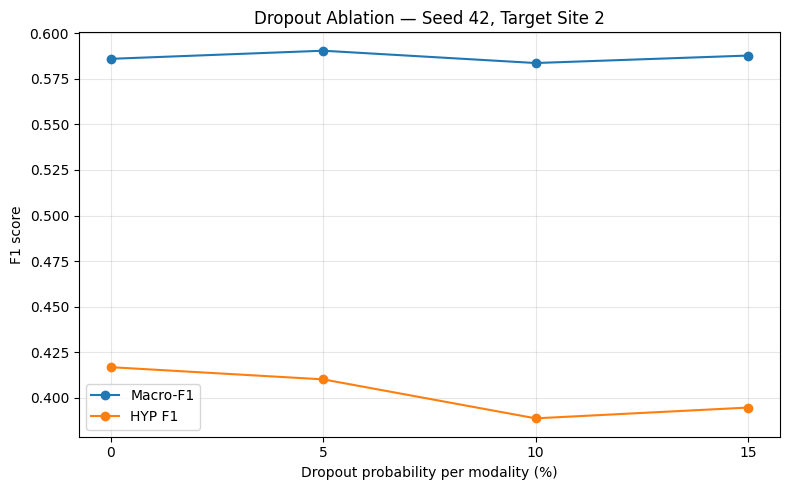

Plot saved: /content/gdrive/MyDrive/mm-dg-healthcare-data/final_results_summary/dropout_ablation_seed42.png


In [68]:

from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

backup = Path(
    "/content/gdrive/MyDrive/mm-dg-healthcare-data/results_backup"
)
out = Path(
    "/content/gdrive/MyDrive/mm-dg-healthcare-data/final_results_summary"
)
out.mkdir(parents=True, exist_ok=True)

runs = [
    (0, "fusion_metadata_site1v2"),
    (5, "fusion_metadata_dropout05_seed42"),
    (10, "fusion_metadata_dropout10_seed42"),
    (15, "fusion_metadata_robust_site1v2"),
]

rows = []
for rate, folder in runs:
    path = backup / folder / "metrics.json"
    if not path.exists():
        print(f"Not available yet: {path}")
        continue

    result = json.loads(path.read_text())
    full = result["target_metrics"]["full"]
    signal = result["target_metrics"]["signal_only"]
    metadata = result["target_metrics"]["metadata_only"]

    rows.append({
        "dropout_percent": rate,
        "accuracy": full["accuracy"],
        "macro_f1": full["macro_f1"],
        "hyp_f1": full["rare_class_f1"],
        "hyp_precision": full["rare_class_precision"],
        "hyp_recall": full["rare_class_recall"],
        "full_minus_signal_only_hyp_f1":
            full["rare_class_f1"] - signal["rare_class_f1"],
        "metadata_only_hyp_f1": metadata["rare_class_f1"],
    })

df = pd.DataFrame(rows).sort_values("dropout_percent")
csv_path = out / "dropout_ablation_seed42.csv"
df.to_csv(csv_path, index=False)

print("Comparison:")
display(df.round(4))
print("CSV saved:", csv_path)

# Plot macro-F1 and HYP F1 against dropout rate.
if not df.empty:
    plt.figure(figsize=(8, 5))
    plt.plot(df["dropout_percent"], df["macro_f1"],
             marker="o", label="Macro-F1")
    plt.plot(df["dropout_percent"], df["hyp_f1"],
             marker="o", label="HYP F1")
    plt.xlabel("Dropout probability per modality (%)")
    plt.ylabel("F1 score")
    plt.title("Dropout Ablation — Seed 42, Target Site 2")
    plt.xticks(df["dropout_percent"])
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()

    plot_path = out / "dropout_ablation_seed42.png"
    plt.savefig(plot_path, dpi=200)
    plt.show()
    print("Plot saved:", plot_path)


In [69]:

from pathlib import Path
import pandas as pd
import shutil

out = Path(
    "/content/gdrive/MyDrive/mm-dg-healthcare-data/final_results_summary"
)

original = out / "final_results_report.md"
updated = out / "final_results_report_with_dropout_ablation.md"
csv_path = out / "dropout_ablation_seed42.csv"
plot_path = out / "dropout_ablation_seed42.png"

# Preserve the original report; create a separate updated copy.
if original.exists():
    report = original.read_text()
else:
    report = (
        "# Research Results Report\n\n"
        "Robust Multimodal Fusion for Cross-Dataset "
        "Generalization in Rare-Class ECG Detection "
        "Under Missing-Modality Conditions\n\n"
        "## Existing Results\n\n"
        "The original report was not found at the expected path. "
        "This document contains the new ablation section only.\n"
    )

# Load the actual saved comparison rather than manually reconstructing metrics.
df = pd.read_csv(csv_path)

expected = {0, 5, 10, 15}
available = set(df["dropout_percent"].astype(int))
if available != expected:
    raise ValueError(
        f"Expected dropout settings {expected}, found {available}. "
        "Check the comparison CSV before updating the report."
    )

rows = []
for _, r in df.sort_values("dropout_percent").iterrows():
    rows.append(
        f"| {int(r['dropout_percent'])}% "
        f"| {r['accuracy']:.4f} "
        f"| {r['macro_f1']:.4f} "
        f"| {r['hyp_f1']:.4f} "
        f"| {r['hyp_precision']:.4f} "
        f"| {r['hyp_recall']:.4f} |"
    )

section = """
## Additional Experiment: Dropout-Rate Ablation (Seed 42)

### Experimental setup

An additional exploratory ablation compared modality-dropout probabilities
of 0%, 5%, 10%, and 15% for each modality. The signal and metadata modalities
were dropped mutually exclusively during training. All four runs used seed 42,
source site 1, and target site 2. The reported metrics are from the full-modality
evaluation on the target site. The checkpoint was selected using source-site
validation, not target-site performance.

### Target-site results

| Dropout per modality | Accuracy | Macro-F1 | HYP F1 | HYP Precision | HYP Recall |
|---|---:|---:|---:|---:|---:|
""" + "\n".join(rows) + """

![Dropout ablation: macro-F1 and HYP F1 by dropout rate](dropout_ablation_seed42.png)

### Interpretation

The 5% setting achieved the highest macro-F1 among these four seed-42 runs.
The 0% baseline achieved the highest HYP F1. The 15% setting achieved the
highest accuracy, while the 10% setting had the lowest HYP F1 and HYP recall.

These results suggest a trade-off between overall classification performance
and rare-class detection. The pattern is not monotonic: increasing dropout
does not consistently improve either macro-F1 or HYP F1. Therefore, these
results do not establish a universally optimal dropout rate.

### Missing-modality evaluation

The difference between full-modality HYP F1 and signal-only HYP F1 was small
across these runs. The values were 0.0057, 0.0052, 0.0022, and -0.0030 for
0%, 5%, 10%, and 15% dropout, respectively. These are descriptive differences
for a single seed, not evidence of a statistically reliable effect.

The metadata-only evaluation produced HYP F1 of zero for all four runs.
This indicates that the evaluated metadata-only condition did not identify
HYP cases successfully on this target site.

### Limitations

- Each dropout-rate result uses only seed 42.
- Results from this ablation are exploratory and should not be treated as
  statistically significant or as proof that one dropout rate is optimal.
- The study evaluates one target site; cross-site generalization across
  additional target domains remains to be established.
- The original three-seed baseline-versus-robust comparison remains the
  primary evidence. This single-seed ablation supplements rather than replaces it.
- The signal-only and metadata-only figures are evaluation conditions for the
  trained fusion model; they are not equivalent to separately trained models.

### Reproducibility artifacts

- `dropout_ablation_seed42.csv`
- `dropout_ablation_seed42.png`
- `results_backup/fusion_metadata_dropout05_seed42/`
- `results_backup/fusion_metadata_dropout10_seed42/` (if the run was completed)

"""

# Make rerunning this cell safe: replace this section if already present.
marker = "## Additional Experiment: Dropout-Rate Ablation (Seed 42)"
if marker in report:
    report = report.split(marker)[0].rstrip() + "\n\n"

updated.write_text(report.rstrip() + "\n\n" + section.strip() + "\n")

print("Updated report copy saved:")
print(updated)
print("\nOriginal report preserved:", original.exists())
print("Plot available:", plot_path.exists())
print("CSV available:", csv_path.exists())
print("\nReport size:", round(updated.stat().st_size / 1024, 1), "KB")


Updated report copy saved:
/content/gdrive/MyDrive/mm-dg-healthcare-data/final_results_summary/final_results_report_with_dropout_ablation.md

Original report preserved: True
Plot available: True
CSV available: True

Report size: 7.0 KB


In [70]:

from pathlib import Path
import shutil

repo = Path("/content/mm-dg-healthcare")
drive = Path("/content/gdrive/MyDrive/mm-dg-healthcare-data")
summary = drive / "final_results_summary"

reports = repo / "reports"
reports.mkdir(parents=True, exist_ok=True)

files = {
    summary / "final_results_report_with_dropout_ablation.md":
        reports / "final_results_report.md",
    summary / "dropout_ablation_seed42.csv":
        repo / "experiments/results/dropout_ablation_seed42.csv",
    summary / "dropout_ablation_seed42.png":
        repo / "experiments/results/dropout_ablation_seed42.png",
}

for source, destination in files.items():
    if not source.exists():
        print("MISSING:", source)
        continue
    destination.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(source, destination)
    print("Copied:", destination.relative_to(repo))


Copied: reports/final_results_report.md
Copied: experiments/results/dropout_ablation_seed42.csv
Copied: experiments/results/dropout_ablation_seed42.png


In [78]:

%cd /content/mm-dg-healthcare

!git status --short
!git add reports/final_results_report.md \
  experiments/results/dropout_ablation_seed42.csv \
  experiments/results/dropout_ablation_seed42.png
!git commit -m "Add dropout ablation results and report"


/content/mm-dg-healthcare
A  reports/final_results_report.md
?? configs/fusion_metadata_dropout05_seed42.yaml
?? configs/fusion_metadata_dropout10_seed42.yaml
The following paths are ignored by one of your .gitignore files:
experiments/results/dropout_ablation_seed42.csv
experiments/results/dropout_ablation_seed42.png
hint: Use -f if you really want to add them.
hint: Turn this message off by running
hint: "git config advice.addIgnoredFile false"
[main df925ee] Add dropout ablation results and report
 1 file changed, 136 insertions(+)
 create mode 100644 reports/final_results_report.md


In [79]:

%cd /content/mm-dg-healthcare

!git add reports/final_results_report.md
!git add configs/fusion_metadata_dropout05_seed42.yaml
!git add configs/fusion_metadata_dropout10_seed42.yaml

# Force-add only the two small ablation artifacts.
!git add -f experiments/results/dropout_ablation_seed42.csv
!git add -f experiments/results/dropout_ablation_seed42.png

!git status --short


/content/mm-dg-healthcare
A  configs/fusion_metadata_dropout05_seed42.yaml
A  configs/fusion_metadata_dropout10_seed42.yaml
A  experiments/results/dropout_ablation_seed42.csv
A  experiments/results/dropout_ablation_seed42.png


In [80]:

%cd /content/mm-dg-healthcare

!git commit -m "Add dropout ablation artifacts and configs"


/content/mm-dg-healthcare
[main 0331e51] Add dropout ablation artifacts and configs
 4 files changed, 73 insertions(+)
 create mode 100644 configs/fusion_metadata_dropout05_seed42.yaml
 create mode 100644 configs/fusion_metadata_dropout10_seed42.yaml
 create mode 100644 experiments/results/dropout_ablation_seed42.csv
 create mode 100644 experiments/results/dropout_ablation_seed42.png


In [81]:

%cd /content/mm-dg-healthcare

!git push origin main


/content/mm-dg-healthcare
fatal: could not read Username for 'https://github.com': No such device or address


In [83]:

from pathlib import Path

ROOT = Path("/content/mm-dg-healthcare")
assert ROOT.exists(), f"Repository not found: {ROOT}"

keywords = [
    "modality_dropout",
    "p_drop_signal",
    "p_drop_metadata",
    "cross_entropy",
    "class_weights",
    "class_weight",
    "missing",
    "signal_only",
    "metadata_only",
]

files_to_check = [
    ROOT / "src/training/trainer_fusion.py",
    ROOT / "src/data/ptbxl_dataset.py",
    ROOT / "configs/fusion_metadata.yaml",
    ROOT / "configs/fusion_robust.yaml",
    ROOT / "configs/fusion_metadata_dropout05_seed42.yaml",
    ROOT / "configs/fusion_metadata_dropout10_seed42.yaml",
]

for path in files_to_check:
    print(f"\n{'=' * 20} {path.relative_to(ROOT)} {'=' * 20}")
    if not path.exists():
        print("NOT FOUND")
        continue

    lines = path.read_text(errors="replace").splitlines()
    matched = set()

    for i, line in enumerate(lines):
        if any(k in line.lower() for k in keywords):
            for j in range(max(0, i - 2), min(len(lines), i + 3)):
                matched.add(j)

    for j in sorted(matched):
        print(f"{j + 1:4}: {lines[j]}")



==================== src/training/trainer_fusion.py ====================
  30:         for b in loader:
  31:             signal=b["signal"].to(device); metadata=b["metadata"].to(device); y=b["label"].numpy()
  32:             if mode == "metadata_only": logits=model(metadata)
  33:             elif condition == "signal_only": logits=model(signal=signal, metadata=None)
  34:             elif condition == "metadata_only": logits=model(signal=None, metadata=metadata)
  35:             else: logits=model(signal=signal, metadata=metadata)
  36:             preds.extend(logits.argmax(1).cpu().numpy()); labels.extend(y)
  71:     rare_name=str(cfg.rare_class.get("name","HYP")); rare_idx=labels[rare_name]
  72:     best=-1.0; history=[]
  73:     p_drop_signal=float(cfg.get("modality_dropout",{}).get("p_drop_signal",0.0)) if cfg.get("modality_dropout",{}).get("enabled",False) else 0.0
  74:     p_drop_meta=float(cfg.get("modality_dropout",{}).get("p_drop_metadata",0.0)) if cfg.get("modality_

In [84]:

from pathlib import Path
import json

ROOT = Path("/content/mm-dg-healthcare")

# 1. Find the model implementation and missing-modality logic.
for path in (ROOT / "src").rglob("*.py"):
    try:
        lines = path.read_text(errors="replace").splitlines()
    except Exception:
        continue

    hits = [
        i for i, line in enumerate(lines)
        if any(term in line.lower() for term in [
            "class fusion", "def forward", "drop_signal_mask",
            "drop_metadata_mask", "metadata is none", "signal is none"
        ])
    ]
    if hits:
        print(f"\n{'=' * 15} {path.relative_to(ROOT)} {'=' * 15}")
        shown = set()
        for i in hits:
            for j in range(max(0, i-3), min(len(lines), i+9)):
                if j not in shown:
                    print(f"{j+1:4}: {lines[j]}")
                    shown.add(j)

# 2. Read the six primary runs' existing metrics.
run_names = [
    "fusion_metadata_site1v2",
    "fusion_metadata_baseline_seed21",
    "fusion_metadata_baseline_seed123",
    "fusion_metadata_robust_site1v2",
    "fusion_metadata_robust_seed21",
    "fusion_metadata_robust_seed123",
]

for name in run_names:
    path = ROOT / "experiments/results" / name / "metrics.json"
    print(f"\n--- {name} ---")
    if not path.exists():
        print("Metrics file not found locally")
        continue

    data = json.loads(path.read_text())
    for condition, metrics in data.get("target_metrics", {}).items():
        print(condition, {
            k: metrics.get(k)
            for k in ["accuracy", "macro_f1", "rare_class_f1",
                      "rare_class_precision", "rare_class_recall"]
            if k in metrics
        })



=============== src/models/fusion.py ===============
   7: from src.models.classifier import ClassifierHead
   8: 
   9: 
  10: class FusionClassifier(nn.Module):
  11:     """Fuse two embeddings; either modality may be absent at inference.
  12: 
  13:     Encoders must return ``(batch, embed_dim)``. Missing modalities are
  14:     represented by learned vectors, allowing full/signal-only/metadata-only
  15:     evaluation with the same trained classifier.
  16:     """
  17:     def __init__(self, signal_encoder: nn.Module, metadata_encoder: nn.Module,
  18:                  fusion_strategy: str = "concat", num_classes: int = 5,
  32:         nn.init.normal_(self.missing_metadata, std=0.02)
  33:         self.head = ClassifierHead(signal_embed_dim + metadata_embed_dim, num_classes, hidden_dim)
  34: 
  35:     def embed(self, signal=None, metadata=None, drop_signal_mask=None, drop_metadata_mask=None):
  36:         reference = signal if signal is not None else metadata
  37:       

In [85]:

from pathlib import Path

root = Path("/content/mm-dg-healthcare")
trainer = root / "src/training/trainer_fusion.py"

lines = trainer.read_text().splitlines()

# Show the imports, model/loss initialization and training setup.
for start, end in [(1, 70), (70, 100)]:
    print(f"\n--- trainer_fusion.py lines {start}-{end} ---")
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i+1:4}: {lines[i]}")

print("\n--- Config files ---")
for path in sorted((root / "configs").glob("*fusion*")):
    print(path.name)



--- trainer_fusion.py lines 1-70 ---
   1: """Train/evaluate ECG + age/sex metadata fusion without target-site selection."""
   2: from __future__ import annotations
   3: import argparse, json, time
   4: from pathlib import Path
   5: import numpy as np
   6: import pandas as pd
   7: import torch
   8: from sklearn.model_selection import train_test_split
   9: from torch.utils.data import DataLoader
  10: from tqdm import tqdm
  11: 
  12: from src.data.ptbxl_dataset import DIAGNOSTIC_SUPERCLASSES, load_ptbxl_metadata
  13: from src.data.ptbxl_multimodal_dataset import PTBXLMetadataDataset
  14: from src.evaluation.metrics import compute_metrics
  15: from src.models.classifier import SignalOnlyClassifier
  16: from src.models.fusion import FusionClassifier
  17: from src.models.metadata_encoder import MetadataEncoder
  18: from src.models.signal_encoder import SignalEncoder
  19: from src.utils.config import load_config, save_config
  20: from src.utils.seed import set_seed, worke

In [86]:

from pathlib import Path
import shutil
import yaml

ROOT = Path("/content/mm-dg-healthcare")
trainer = ROOT / "src/training/trainer_fusion.py"
base_config = ROOT / "configs/fusion_metadata.yaml"

assert trainer.exists(), f"Missing trainer: {trainer}"
assert base_config.exists(), f"Missing config: {base_config}"

# Preserve the original trainer before patching.
backup = trainer.with_suffix(".py.pre_classweight_backup")
if not backup.exists():
    shutil.copy2(trainer, backup)
    print("Trainer backup:", backup)
else:
    print("Existing trainer backup preserved:", backup)

source = trainer.read_text()

old = "    criterion=torch.nn.CrossEntropyLoss()"
new = '''    loss_cfg = cfg.get("loss", {})
    if loss_cfg.get("class_weighted", False):
        counts = train_df["superclass"].map(labels).value_counts()
        counts = np.array([int((train_df["superclass"] == c).sum())
                           for c in DIAGNOSTIC_SUPERCLASSES], dtype=np.float64)
        if np.any(counts == 0):
            raise ValueError(f"Missing class in source training split: {counts}")
        class_weights = len(train_df) / (len(labels) * counts)
        criterion = torch.nn.CrossEntropyLoss(
            weight=torch.tensor(class_weights, dtype=torch.float32, device=device)
        )
        print("Class-weighted cross-entropy weights:",
              dict(zip(DIAGNOSTIC_SUPERCLASSES, class_weights.round(4))))
    else:
        criterion = torch.nn.CrossEntropyLoss()'''

if old in source:
    trainer.write_text(source.replace(old, new, 1))
    print("Trainer patched with optional class weighting.")
elif new in source:
    print("Class-weighting patch already present; no change needed.")
else:
    raise RuntimeError(
        "Could not safely locate criterion initialization. "
        "No automatic patch made; inspect trainer_fusion.py."
    )

# Create a separate config; leave the existing configs untouched.
cfg = yaml.safe_load(base_config.read_text())
cfg["seed"] = 42
cfg.setdefault("loss", {})["class_weighted"] = True
cfg["output"]["run_dir"] = (
    "experiments/results/fusion_metadata_classweighted_seed42"
)

new_config = ROOT / "configs/fusion_metadata_classweighted_seed42.yaml"
new_config.write_text(yaml.safe_dump(cfg, sort_keys=False))

print("\nNew config:", new_config)
print("Output directory:", cfg["output"]["run_dir"])
print("Train sites:", cfg["data"]["train_sites"])
print("Target sites:", cfg["data"]["test_sites"])
print("Epochs:", cfg["train"]["epochs"])
print("Batch size:", cfg["train"]["batch_size"])
print("\nSetup complete. Do not start training until these settings look correct.")


Trainer backup: /content/mm-dg-healthcare/src/training/trainer_fusion.py.pre_classweight_backup
Trainer patched with optional class weighting.

New config: /content/mm-dg-healthcare/configs/fusion_metadata_classweighted_seed42.yaml
Output directory: experiments/results/fusion_metadata_classweighted_seed42
Train sites: [1]
Target sites: [2]
Epochs: 20
Batch size: 32

Setup complete. Do not start training until these settings look correct.


In [87]:

%cd /content/mm-dg-healthcare
!python -m src.training.trainer_fusion --config configs/fusion_metadata_classweighted_seed42.yaml


/content/mm-dg-healthcare
Device: cuda
Class-weighted cross-entropy weights: {'NORM': np.float64(0.45), 'MI': np.float64(1.5157), 'STTC': np.float64(1.0536), 'CD': np.float64(1.214), 'HYP': np.float64(2.8989)}
epoch 1/20 loss=1.3188 val_rare_f1=0.4145 val_macro_f1=0.4993
epoch 2/20 loss=1.0776 val_rare_f1=0.3902 val_macro_f1=0.4852
epoch 3/20 loss=0.9831 val_rare_f1=0.3871 val_macro_f1=0.4406
epoch 4/20 loss=0.9471 val_rare_f1=0.3575 val_macro_f1=0.5480
epoch 5/20 loss=0.8992 val_rare_f1=0.3552 val_macro_f1=0.4995
epoch 6/20 loss=0.8658 val_rare_f1=0.3676 val_macro_f1=0.5356
epoch 7/20 loss=0.8228 val_rare_f1=0.3376 val_macro_f1=0.5257
epoch 8/20 loss=0.8054 val_rare_f1=0.3366 val_macro_f1=0.5256
epoch 9/20 loss=0.7640 val_rare_f1=0.4586 val_macro_f1=0.5901
epoch 10/20 loss=0.7212 val_rare_f1=0.3091 val_macro_f1=0.5135
epoch 11/20 loss=0.7035 val_rare_f1=0.3942 val_macro_f1=0.5781
epoch 12/20 loss=0.6464 val_rare_f1=0.3182 val_macro_f1=0.5204
epoch 13/20 loss=0.6275 val_rare_f1=0.3850 

In [88]:

from pathlib import Path
import shutil
import json

ROOT = Path("/content/mm-dg-healthcare")
DRIVE = Path("/content/gdrive/MyDrive/mm-dg-healthcare-data")

run_name = "fusion_metadata_classweighted_seed42"
src = ROOT / "experiments/results" / run_name
dst = DRIVE / "results_backup" / run_name

metrics = src / "metrics.json"
checkpoint = src / "best_model.pt"
config = src / "config_used.yaml"

assert metrics.exists(), "Training metrics.json not found."
assert checkpoint.exists(), "Best checkpoint not found."
assert config.exists(), "Saved config not found."

data = json.loads(metrics.read_text())
assert "target_metrics" in data, "Unexpected metrics format."

dst.mkdir(parents=True, exist_ok=True)
for name in [
    "metrics.json", "best_model.pt", "config_used.yaml",
    "history.json", "metadata_normalization.json"
]:
    f = src / name
    if f.exists():
        shutil.copy2(f, dst / name)

print("Backed up to:", dst)
print("Checkpoint epoch:", data.get("checkpoint_epoch"))
print("Target metrics:")
for condition, result in data["target_metrics"].items():
    print(condition, {
        k: result.get(k) for k in [
            "accuracy", "macro_f1", "rare_class_f1",
            "rare_class_precision", "rare_class_recall"
        ]
    })


Backed up to: /content/gdrive/MyDrive/mm-dg-healthcare-data/results_backup/fusion_metadata_classweighted_seed42
Checkpoint epoch: 9
Target metrics:
full {'accuracy': 0.6319984060569834, 'macro_f1': 0.5775248047286647, 'rare_class_f1': 0.4115384615384615, 'rare_class_precision': 0.3807829181494662, 'rare_class_recall': 0.4476987447698745}
signal_only {'accuracy': 0.6080892608089261, 'macro_f1': 0.5589218333713175, 'rare_class_f1': 0.3850085178875639, 'rare_class_precision': 0.32471264367816094, 'rare_class_recall': 0.47280334728033474}
metadata_only {'accuracy': 0.3775652520422395, 'macro_f1': 0.19104516055230877, 'rare_class_f1': 0.0, 'rare_class_precision': 0.0, 'rare_class_recall': 0.0}
metadata_only_baseline {'accuracy': 0.39171149631400676, 'macro_f1': 0.2543591675746665, 'rare_class_f1': 0.0, 'rare_class_precision': 0.0, 'rare_class_recall': 0.0}


In [89]:

from pathlib import Path
import pandas as pd

drive = Path("/content/gdrive/MyDrive/mm-dg-healthcare-data")
summary_dir = drive / "final_results_summary"
summary_dir.mkdir(parents=True, exist_ok=True)

rows = [
    {
        "model": "baseline",
        "seed": 42,
        "accuracy": 0.6487348077,
        "macro_f1": 0.5859331042,
        "HYP_F1": 0.4168336673,
        "HYP_precision": 0.4000000000,
        "HYP_recall": 0.4351464435,
    },
    {
        "model": "class_weighted",
        "seed": 42,
        "accuracy": 0.6319984061,
        "macro_f1": 0.5775248047,
        "HYP_F1": 0.4115384615,
        "HYP_precision": 0.3807829181,
        "HYP_recall": 0.4476987448,
    },
]

df = pd.DataFrame(rows)
pivot = df.set_index("model")
metrics = [
    "accuracy", "macro_f1", "HYP_F1",
    "HYP_precision", "HYP_recall"
]
diff = pivot.loc["class_weighted", metrics] - pivot.loc["baseline", metrics]

df.to_csv(summary_dir / "class_weighting_seed42.csv", index=False)
pd.DataFrame({
    "metric": metrics,
    "baseline": pivot.loc["baseline", metrics].values,
    "class_weighted": pivot.loc["class_weighted", metrics].values,
    "difference": diff.values,
}).to_csv(summary_dir / "class_weighting_seed42_comparison.csv", index=False)

print("Saved comparison files to:", summary_dir)
print(pd.DataFrame({
    "baseline": pivot.loc["baseline", metrics],
    "class_weighted": pivot.loc["class_weighted", metrics],
    "difference": diff,
}).round(4))


Saved comparison files to: /content/gdrive/MyDrive/mm-dg-healthcare-data/final_results_summary
               baseline  class_weighted  difference
accuracy         0.6487          0.6320     -0.0167
macro_f1         0.5859          0.5775     -0.0084
HYP_F1           0.4168          0.4115     -0.0053
HYP_precision    0.4000          0.3808     -0.0192
HYP_recall       0.4351          0.4477      0.0126


In [90]:

from pathlib import Path
import yaml

ROOT = Path("/content/mm-dg-healthcare")
base_path = ROOT / "configs/fusion_metadata.yaml"

base = yaml.safe_load(base_path.read_text())

for seed in [21, 123]:
    cfg = yaml.safe_load(base_path.read_text())
    cfg["seed"] = seed
    cfg.setdefault("loss", {})["class_weighted"] = True
    cfg["output"]["run_dir"] = (
        f"experiments/results/fusion_metadata_classweighted_seed{seed}"
    )

    path = ROOT / "configs" / f"fusion_metadata_classweighted_seed{seed}.yaml"
    path.write_text(yaml.safe_dump(cfg, sort_keys=False))

    print(f"\nCreated: {path.name}")
    print("Seed:", cfg["seed"])
    print("Train sites:", cfg["data"]["train_sites"])
    print("Test sites:", cfg["data"]["test_sites"])
    print("Epochs:", cfg["train"]["epochs"])
    print("Batch size:", cfg["train"]["batch_size"])
    print("Output:", cfg["output"]["run_dir"])



Created: fusion_metadata_classweighted_seed21.yaml
Seed: 21
Train sites: [1]
Test sites: [2]
Epochs: 20
Batch size: 32
Output: experiments/results/fusion_metadata_classweighted_seed21

Created: fusion_metadata_classweighted_seed123.yaml
Seed: 123
Train sites: [1]
Test sites: [2]
Epochs: 20
Batch size: 32
Output: experiments/results/fusion_metadata_classweighted_seed123


In [91]:

%cd /content/mm-dg-healthcare
!python -m src.training.trainer_fusion --config configs/fusion_metadata_classweighted_seed21.yaml


/content/mm-dg-healthcare
Device: cuda
Class-weighted cross-entropy weights: {'NORM': np.float64(0.45), 'MI': np.float64(1.5157), 'STTC': np.float64(1.0536), 'CD': np.float64(1.214), 'HYP': np.float64(2.8989)}
epoch 1/20 loss=1.3386 val_rare_f1=0.4808 val_macro_f1=0.5343
epoch 2/20 loss=1.0909 val_rare_f1=0.5079 val_macro_f1=0.5762
epoch 3/20 loss=1.0298 val_rare_f1=0.5000 val_macro_f1=0.5976
epoch 4/20 loss=0.9850 val_rare_f1=0.5029 val_macro_f1=0.5540
epoch 5/20 loss=0.9339 val_rare_f1=0.4821 val_macro_f1=0.5759
epoch 6/20 loss=0.9015 val_rare_f1=0.4898 val_macro_f1=0.6112
epoch 7/20 loss=0.8569 val_rare_f1=0.4651 val_macro_f1=0.6203
epoch 8/20 loss=0.8106 val_rare_f1=0.4407 val_macro_f1=0.5154
epoch 9/20 loss=0.8054 val_rare_f1=0.4719 val_macro_f1=0.6228
epoch 10/20 loss=0.7572 val_rare_f1=0.4497 val_macro_f1=0.6091
epoch 11/20 loss=0.7384 val_rare_f1=0.3271 val_macro_f1=0.4973
epoch 12/20 loss=0.7099 val_rare_f1=0.3906 val_macro_f1=0.5622
epoch 13/20 loss=0.6648 val_rare_f1=0.4533 

In [92]:

from pathlib import Path
import shutil
import json

ROOT = Path("/content/mm-dg-healthcare")
DRIVE = Path("/content/gdrive/MyDrive/mm-dg-healthcare-data")

def backup_run(seed):
    name = f"fusion_metadata_classweighted_seed{seed}"
    src = ROOT / "experiments/results" / name
    dst = DRIVE / "results_backup" / name

    required = ["metrics.json", "best_model.pt", "config_used.yaml"]
    missing = [f for f in required if not (src / f).exists()]
    if missing:
        raise FileNotFoundError(f"{name}: missing {missing}")

    dst.mkdir(parents=True, exist_ok=True)
    for f in src.iterdir():
        if f.is_file():
            shutil.copy2(f, dst / f.name)

    data = json.loads((dst / "metrics.json").read_text())
    print(f"\nBacked up: {dst}")
    print("Checkpoint epoch:", data.get("checkpoint_epoch"))
    for condition, m in data["target_metrics"].items():
        print(condition, {
            k: m.get(k) for k in [
                "accuracy", "macro_f1", "rare_class_f1",
                "rare_class_precision", "rare_class_recall"
            ]
        })

backup_run(21)



Backed up: /content/gdrive/MyDrive/mm-dg-healthcare-data/results_backup/fusion_metadata_classweighted_seed21
Checkpoint epoch: 2
full {'accuracy': 0.6007172743574417, 'macro_f1': 0.5175846677022029, 'rare_class_f1': 0.3904109589041096, 'rare_class_precision': 0.33043478260869563, 'rare_class_recall': 0.4769874476987448}
signal_only {'accuracy': 0.5837816298067344, 'macro_f1': 0.501993599324692, 'rare_class_f1': 0.37116564417177916, 'rare_class_precision': 0.2929782082324455, 'rare_class_recall': 0.5062761506276151}
metadata_only {'accuracy': 0.3241681609882447, 'macro_f1': 0.22791489201474463, 'rare_class_f1': 0.0, 'rare_class_precision': 0.0, 'rare_class_recall': 0.0}
metadata_only_baseline {'accuracy': 0.3588364215979279, 'macro_f1': 0.2699922053584217, 'rare_class_f1': 0.09856262833675565, 'rare_class_precision': 0.0653061224489796, 'rare_class_recall': 0.200836820083682}


In [93]:

%cd /content/mm-dg-healthcare
!python -m src.training.trainer_fusion --config configs/fusion_metadata_classweighted_seed123.yaml


/content/mm-dg-healthcare
Device: cuda
Class-weighted cross-entropy weights: {'NORM': np.float64(0.45), 'MI': np.float64(1.5157), 'STTC': np.float64(1.0536), 'CD': np.float64(1.214), 'HYP': np.float64(2.8989)}
epoch 1/20 loss=1.3049 val_rare_f1=0.4695 val_macro_f1=0.5469
epoch 2/20 loss=1.0848 val_rare_f1=0.5137 val_macro_f1=0.5782
epoch 3/20 loss=1.0071 val_rare_f1=0.4889 val_macro_f1=0.5676
epoch 4/20 loss=0.9577 val_rare_f1=0.5025 val_macro_f1=0.5933
epoch 5/20 loss=0.9158 val_rare_f1=0.4286 val_macro_f1=0.5778
epoch 6/20 loss=0.8689 val_rare_f1=0.4192 val_macro_f1=0.5632
epoch 7/20 loss=0.8283 val_rare_f1=0.4571 val_macro_f1=0.5639
epoch 8/20 loss=0.8062 val_rare_f1=0.4348 val_macro_f1=0.5430
epoch 9/20 loss=0.7695 val_rare_f1=0.4627 val_macro_f1=0.5739
epoch 10/20 loss=0.7531 val_rare_f1=0.4800 val_macro_f1=0.5602
epoch 11/20 loss=0.7078 val_rare_f1=0.4094 val_macro_f1=0.5480
epoch 12/20 loss=0.6876 val_rare_f1=0.4100 val_macro_f1=0.5655
epoch 13/20 loss=0.6393 val_rare_f1=0.4554 

In [94]:

backup_run(123)



Backed up: /content/gdrive/MyDrive/mm-dg-healthcare-data/results_backup/fusion_metadata_classweighted_seed123
Checkpoint epoch: 2
full {'accuracy': 0.6096832038254633, 'macro_f1': 0.5294076264529102, 'rare_class_f1': 0.38848920863309355, 'rare_class_precision': 0.34069400630914826, 'rare_class_recall': 0.45188284518828453}
signal_only {'accuracy': 0.5811914724048616, 'macro_f1': 0.5128018235319719, 'rare_class_f1': 0.3717948717948718, 'rare_class_precision': 0.3012987012987013, 'rare_class_recall': 0.48535564853556484}
metadata_only {'accuracy': 0.42398884239888424, 'macro_f1': 0.1846690961091026, 'rare_class_f1': 0.0, 'rare_class_precision': 0.0, 'rare_class_recall': 0.0}
metadata_only_baseline {'accuracy': 0.3564455070731221, 'macro_f1': 0.26837256246318936, 'rare_class_f1': 0.10452961672473868, 'rare_class_precision': 0.066006600660066, 'rare_class_recall': 0.2510460251046025}


In [95]:

from google.colab import _message
from pathlib import Path
from datetime import datetime
import json

# Current notebook contents from the active Colab session
notebook = _message.blocking_request(
    "get_ipynb",
    request="get_ipynb"
)

if not notebook or "ipynb" not in notebook:
    raise RuntimeError(
        "Could not retrieve the active notebook. "
        "Use File > Save a copy in Drive instead."
    )

from google.colab import drive
drive.mount("/content/gdrive", force_remount=False)

folder = Path(
    "/content/gdrive/MyDrive/mm-dg-healthcare-data/notebooks"
)
folder.mkdir(parents=True, exist_ok=True)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
path = folder / f"mm_dg_healthcare_research_{timestamp}.ipynb"

content = notebook["ipynb"]
if isinstance(content, dict):
    path.write_text(json.dumps(content, indent=2))
else:
    path.write_text(content)

print("Notebook backup saved:", path)
print("File size:", round(path.stat().st_size / 1024, 1), "KB")


Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).
Notebook backup saved: /content/gdrive/MyDrive/mm-dg-healthcare-data/notebooks/mm_dg_healthcare_research_20261022_123327.ipynb
File size: 416.5 KB
